# Projet de Data Science : Prédiction de la gravité des accidents de la route en France (2005 - 2016)

## 1. Titre et objectif du projet

### Contexte
La sécurité routière demeure un enjeu majeur de santé publique et d'aménagement du territoire en France. Pouvoir anticiper et analyser les facteurs de gravité des accidents corporels permet de guider les politiques de prévention routière et de cibler les aménagements d'infrastructure les plus critiques.

### Objectif Machine Learning
L'objectif de ce projet est de développer un modèle d'apprentissage automatique supervisé (tâche de classification) capable de prédire la gravité d'un accident de la route à partir de ses caractéristiques (conditions atmosphériques, caractéristiques du lieu, profil de la route, types de véhicules impliqués, profils des usagers).

---

## 2. Sources et liens

- **Dataset Kaggle** : [Accidents in France from 2005 to 2016](https://www.kaggle.com/datasets/ahmedlahlou/accidents-in-france-from-2005-to-2016) par Ahmed Lahlou.
- **Source originale** : Base BAAC (Bulletins d'Analyse des Accidents Corporels de la circulation), produite par l'ONISR (Observatoire national interministériel de la sécurité routière) à partir des fiches saisies par les forces de l'ordre.
- **Hébergement du projet** : Les 5 fichiers de données seront hébergés sur le dépôt GitHub du projet https://github.com/mathieu10266/AAA_Prediction-de-la-gravite-des-accidents-de-la-route-en-France.

**Note méthodologique** : Le jeu de données ne recense que les accidents corporels (impliquant au moins une victime). Il n'y a donc aucun accident purement matériel (sans blessé ou tué) documenté dans cette base.

---

## 3. Pourquoi 5 fichiers ?

### Modèle relationnel et granularité
Le jeu de données d'origine est découpé en 5 tables distinctes. Ce choix de modélisation relationnelle évite la redondance massive d'informations. En effet, un accident donné survient en un lieu unique, mais peut impliquer plusieurs véhicules, chacun de ces véhicules transportant plusieurs usagers.

Si l'on construisait une unique table « plate » dès le départ, les informations générales de l'accident et du lieu de la route seraient dupliquées pour chaque usager impliqué, ce qui alourdirait artificiellement le volume de stockage et complexifierait les niveaux d'analyses.

### Rôle de chaque fichier
- **caracteristics.csv** : Décrit les circonstances temporelles, spatiales et lumineuses générales de l'accident.
- **places.csv** : Décrit l'infrastructure routière et la configuration physique de la chaussée au lieu de l'accident.
- **vehicles.csv** : Liste chaque véhicule impliqué dans l'accident.
- **users.csv** : Contient les informations individuelles de chaque usager (conducteur, passager, piéton) ainsi que la variable cible de gravité (`grav`).
- **holidays.csv** : Fournit un calendrier des jours fériés pour la période concernée, permettant d'enrichir l'analyse temporelle.

---

## 4. Dictionnaire des variables

### Table `caracteristics.csv` (1 ligne par accident)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | entier unique | identifiant |
| **jour** | jour du mois | 1 à 31 | numérique |
| **mois** | mois | 1 à 12 | numérique |
| **an** | année | 5 à 16 (2005 à 2016), sur 2 chiffres | numérique |
| **hrmn** | heure et minute au format HHMM | entier de 1 à 2359 (1445 = 14h45) | date/heure |
| **lum** | conditions d'éclairage | 1 plein jour ; 2 crépuscule ou aube ; 3 nuit sans éclairage public ; 4 nuit avec éclairage public non allumé ; 5 nuit avec éclairage public allumé | catégorie codée |
| **agg** | localisation | 1 hors agglomération ; 2 en agglomération | catégorie codée |
| **int** | type d'intersection | 1 hors intersection ; 2 en X ; 3 en T ; 4 en Y ; 5 à plus de 4 branches ; 6 giratoire ; 7 place ; 8 passage à niveau ; 9 autre ; 0 présent dans les données mais non documenté | catégorie codée |
| **atm** | conditions atmosphériques | 1 normale ; 2 pluie légère ; 3 pluie forte ; 4 neige/grêle ; 5 brouillard/fumée ; 6 vent fort/tempête ; 7 temps éblouissant ; 8 temps couvert ; 9 autre | catégorie codée |
| **col** | type de collision | 1 deux véhicules frontale ; 2 deux véhicules par l'arrière ; 3 deux véhicules par le côté ; 4 trois véhicules ou plus en chaîne ; 5 trois véhicules ou plus (collisions multiples) ; 6 autre collision ; 7 sans collision | catégorie codée |
| **com** | commune | numéro INSEE sur 3 chiffres dans le département (0 à 987), unique seulement avec dep | catégorie codée |
| **adr** | adresse postale | texte libre, renseignée surtout en zone urbaine (17 % de valeurs manquantes) | texte |
| **gps** | origine des coordonnées GPS | M métropole ; A Antilles ; G Guyane ; R Réunion ; Y Mayotte (autres valeurs rares non documentées) | catégorie codée |
| **lat** | latitude | valeur en degrés x 10^5 (ex. 4370200 = 43,702°), beaucoup de 0 et de valeurs manquantes (environ 57 %) | numérique |
| **long** | longitude | même codage que lat, lue comme texte, peut être négative | numérique |
| **dep** | département | code INSEE x 10 (590 = Nord, 750 = Paris, 201 = Corse-du-Sud, 202 = Haute-Corse, 971 à 976 = DOM), 101 valeurs distinctes | catégorie codée |

#### Pourquoi / Choix
Ces caractéristiques temporelles (heure, mois, jour) et d'environnement (lum, atm, col) sont fondamentales car elles capturent le contexte physique global de l'accident, fortement corrélé avec la visibilité et la violence des chocs. Un point d'attention crucial concerne l'exploitation des données de géolocalisation (`lat` et `long`) qui présentent un taux de manquants supérieur à 50% sur l'ensemble du dataset historique et qui nécessitent une multiplication par $10^{-5}$ pour être exploitées en degrés réels.

---

### Table `places.csv` (1 ligne par accident)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **catr** | catégorie de route | 1 autoroute ; 2 route nationale ; 3 route départementale ; 4 voie communale ; 5 hors réseau public ; 6 parking ouvert à la circulation publique ; 9 autre | catégorie codée |
| **voie** | numéro de la route | texte | texte |
| **v1** | indice numérique du numéro de route | 0 à 9, environ 60 % de valeurs manquantes | numérique |
| **v2** | indice alphanumérique de la route | lettre, environ 96 % de valeurs manquantes | catégorie codée |
| **circ** | régime de circulation | 1 sens unique ; 2 bidirectionnelle ; 3 chaussées séparées ; 4 voies d'affectation variable ; 0 non documenté | catégorie codée |
| **nbv** | nombre total de voies de circulation | entier de 0 à 99 (valeurs élevées suspectes) | numérique |
| **vosp** | voie réservée existante | 1 piste cyclable ; 2 bande cyclable ; 3 voie réservée ; 0 sans objet | catégorie codée |
| **prof** | profil en long (pente de la route) | 1 plat ; 2 pente ; 3 sommet de côte ; 4 bas de côte ; 0 non renseigné | catégorie codée |
| **pr** | numéro du point de repère (PR) amont | 0 à 9900, environ 51 % de valeurs manquantes | numérique |
| **pr1** | distance en mètres au PR | 0 à 9540, environ 51 % de valeurs manquantes | numérique |
| **plan** | tracé en plan | 1 partie rectiligne ; 2 courbe à gauche ; 3 courbe à droite ; 4 en S ; 0 non renseigné | catégorie codée |
| **lartpc** | largeur du terre-plein central s'il existe | unité non précisée par Kaggle (mètres selon l'ONISR), valeurs aberrantes jusqu'à 960 | numérique |
| **larrout** | largeur de la chaussée réservée aux véhicules | valeurs de -81 à 999, donc aberrantes | numérique |
| **surf** | état de la surface | 1 normale ; 2 mouillée ; 3 flaques ; 4 inondée ; 5 enneigée ; 6 boue ; 7 verglacée ; 8 corps gras/huile ; 9 autre ; 0 non renseigné | catégorie codée |
| **infra** | aménagement / infrastructure | 1 souterrain/tunnel ; 2 pont/autopont ; 3 bretelle d'échangeur ou de raccordement ; 4 voie ferrée ; 5 carrefour aménagé ; 6 zone piétonne ; 7 zone de péage ; 0 aucun | catégorie codée |
| **situ** | situation de l'accident | 1 sur chaussée ; 2 sur bande d'arrêt d'urgence ; 3 sur accotement ; 4 sur trottoir ; 5 sur piste cyclable ; 0 aucun | catégorie codée |
| **env1** | point scolaire, proximité d'une école | seulement 0, 3 et 99 dans les données, codes non détaillés : à utiliser avec prudence | catégorie codée |

#### Pourquoi / Choix
La catégorie de route (`catr`) et le profil en long (`prof`) sont des proxies directs de la vitesse autorisée et de la visibilité sur la route (ex: vitesse accrue sur autoroute engendrant potentiellement des chocs plus graves). Cependant, plusieurs variables physiques comme `lartpc`, `larrout` ou `nbv` contiennent des anomalies évidentes (valeurs négatives ou hors normes) qui nécessiteront un nettoyage rigoureux lors de l'étape de préparation.

---

### Table `vehicles.csv` (1 ligne par véhicule)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **num_veh** | identifiant du véhicule dans l'accident | texte A01, B02, C03... | identifiant |
| **senc** | sens de circulation | 1 numéro de PR ou PK croissant ; 2 décroissant ; 0 inconnu | catégorie codée |
| **catv** | catégorie du véhicule | 01 vélo ; 02 cyclomoteur < 50 cm3 ; 03 voiturette ; 07 VL seule (la plus fréquente) ; 10 véhicule utilitaire léger ; 13 PL de 3,5 à 7,5 t ; 14 PL > 7,5 t ; 15 PL + remorque ; 16 tracteur routier ; 17 tracteur + semi-remorque ; 20 engin spécial ; 21 tracteur agricole ; 30 scooter < 50 cm3 ; 31 moto 50 à 125 cm3 ; 32 scooter 50 à 125 cm3 ; 33 moto > 125 cm3 ; 34 scooter > 125 cm3 ; 35 quad léger ; 36 quad lourd ; 37 autobus ; 38 autocar ; 39 train ; 40 tramway ; 99 autre (les codes 04, 05, 06, 08, 09, 11, 12, 18, 19 sont d'anciens codes peu utilisés) | catégorie codée |
| **occutc** | nombre d'occupants d'un transport en commun | 0 à 700, 99,3 % de zéros | numérique |
| **obs** | obstacle fixe heurté | 0 aucun ; 1 véhicule en stationnement ; 2 arbre ; 3 à 5 glissières (métal, béton, autre) ; 6 bâtiment/mur/pile de pont ; 7 support de signalisation ; 8 poteau ; 9 mobilier urbain ; 10 parapet ; 11 îlot ou borne haute ; 12 bordure de trottoir ; 13 fossé/talus/paroi ; 14 autre obstacle sur chaussée ; 15 autre obstacle sur trottoir ou accotement ; 16 sortie de chaussée sans obstacle | catégorie codée |
| **obsm** | obstacle mobile heurté | 0 aucun ; 1 piéton ; 2 véhicule ; 4 véhicule sur rail ; 5 animal domestique ; 6 animal sauvage ; 9 autre | catégorie codée |
| **choc** | point de choc initial | 0 aucun ; 1 avant ; 2 avant droit ; 3 avant gauche ; 4 arrière ; 5 arrière droit ; 6 arrière gauche ; 7 côté droit ; 8 côté gauche ; 9 chocs multiples (tonneaux) | catégorie codée |
| **manv** | manoeuvre principale avant l'accident | 0 inconnue ; 1 sans changement de direction ; 2 même sens même file ; 3 entre deux files ; 4 marche arrière ; 5 à contresens ; 6 en franchissant le terre-plein ; 7 et 8 couloir de bus (même sens, sens inverse) ; 9 en s'insérant ; 10 demi-tour ; 11 et 12 changement de file (gauche, droite) ; 13 et 14 déporté (gauche, droite) ; 15 et 16 tournant (gauche, droite) ; 17 et 18 dépassant (gauche, droite) ; 19 traversant la chaussée ; 20 manoeuvre de stationnement ; 21 manoeuvre d'évitement ; 22 ouverture de porte ; 23 arrêté (hors stationnement) ; 24 en stationnement (avec occupants) | catégorie codée |

#### Pourquoi / Choix
La catégorie du véhicule (`catv`) et la présence d'obstacles heurtes (`obs`, `obsm`) sont des facteurs critiques : le taux de mortalité est drastiquement différent entre un cycliste (catégorie 01) heurtant un arbre, et un conducteur de poids lourd (catégorie 14). Le traitement des 09,3% de zéros dans `occutc` demandera une attention particulière car la variable ne s'applique en pratique qu'aux transports en commun.

---

### Table `users.csv` (1 ligne par usager)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **num_veh** | véhicule de l'usager | même codage que dans vehicles | identifiant |
| **place** | place occupée dans le véhicule | 0 à 9 selon un schéma de placement (1 = conducteur), codes non détaillés | catégorie codée |
| **catu** | catégorie d'usager | 1 conducteur ; 2 passager ; 3 piéton ; 4 piéton en roller ou trottinette | catégorie codée |
| **grav** | gravité (**VARIABLE CIBLE**) | 1 indemne ; 2 tué ; 3 blessé hospitalisé ; 4 blessé léger | catégorie codée |
| **sexe** | sexe | 1 masculin ; 2 féminin | catégorie codée |
| **trajet** | motif du déplacement | 0 non renseigné ; 1 domicile-travail ; 2 domicile-école ; 3 courses/achats ; 4 utilisation professionnelle ; 5 promenade/loisirs ; 9 autre | catégorie codée |
| **secu** | équipement de sécurité | 1er chiffre = équipement (1 ceinture ; 2 casque ; 3 dispositif enfant ; 4 équipement réfléchissant ; 9 autre) ; 2e chiffre = utilisation (1 oui ; 2 non ; 3 non déterminable) | catégorie codée |
| **locp** | localisation du piéton | 0 sans objet ; 1 sur chaussée à plus de 50 m d'un passage piéton ; 2 sur chaussée à moins de 50 m ; 3 sur passage piéton sans signalisation lumineuse ; 4 sur passage piéton avec signalisation lumineuse ; 5 sur trottoir ; 6 sur accotement ; 7 en refuge ou bande d'arrêt d'urgence ; 8 sur contre-allée | catégorie codée |
| **actp** | action du piéton | 0 non renseigné ou sans objet ; 1 dans le sens du véhicule heurtant ; 2 dans le sens inverse ; 3 traversant ; 4 masqué ; 5 jouant ou courant ; 6 avec un animal ; 9 autre | catégorie codée |
| **etatp** | piéton seul ou accompagné | 1 seul ; 2 accompagné ; 3 en groupe ; 0 non renseigné ou sans objet | catégorie codée |
| **an_nais** | année de naissance | 1896 à 2016 (âge = 2000 + an - an_nais) | numérique |

#### Pourquoi / Choix
C'est dans cette table que se situe notre variable d'intérêt `grav`. Les attributs individuels de l'usager, tels que son âge (déduit de `an_nais`), l'usage des dispositifs de sécurité (`secu`), ou sa position dans le véhicule (`place`) sont de forts prédicteurs de la vulnérabilité corporelle. Notez que la gravité n'est pas ordonnée de façon strictement croissante avec l'encodage (la modalité `2` représente le décès alors que les blessés sont codés `3` et `4`).

---

### Table `holidays.csv` (1 ligne par jour férié)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **ds** | date du jour férié | de 2005-01-01 à 2016-12-25 | date/heure |
| **holiday** | nom du jour férié | 11 jours fériés nationaux français sur la période | catégorie codée |

#### Pourquoi / Choix
Cette table externe permet d'ajouter une information temporelle de calendrier. Les jours de départ en vacances ou les jours fériés sont historiquement corrélés à des typologies d'accidents spécifiques (fatigue sur longs trajets de loisirs, alcoolémie nocturne accrue).

---

## 5. Limites de la documentation et points d'attention

- **Signification du code 0** : Pour plusieurs variables (`int`, `circ`, `prof`, `plan`, `surf`, `infra`, `situ`, `trajet`, `etatp`), le code 0 représente un statut indéterminé ('non renseigné' ou 'sans objet') et non pas une valeur nulle ou d'absence.
- **Valeurs physiques aberrantes** : Les champs décrivant les largeurs de route (`lartpc`, `larrout`) et le nombre de voies (`nbv`) présentent des extrêmes peu cohérents (largeurs négatives, plus de 90 voies de circulation).
- **Gestion des échelles** : La gravité est renseignée à la ligne d'usager (`users.csv`). Il faudra appliquer des agrégations de type maximum sur l'indicateur de gravité de l'accident.
- **Déséquilibre des classes** : pour la cible binaire retenue (accident grave = au moins un usager tué ou hospitalisé), la répartition est d'environ 44 % / 56 % en 2005, un déséquilibre modéré qui ne nécessite pas de rééquilibrage. Une cible à 3 classes (blessé léger, hospitalisé, tué) aurait une classe "tué" très minoritaire (5,6 % des accidents sur l'ensemble de la période).

## Étape 0 : Chargement et importation des datasets

## Imports des bibliothèques

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

Nous chargeons l'ensemble des 5 fichiers CSV du projet en mémoire sous forme de DataFrames pandas avec les encodages appropriés (`latin-1` pour `caracteristics.csv` et `utf-8` pour les autres).

In [5]:
# Définition des chemins d'accès locaux aux fichiers CSV

# --- Chemins actifs (fichiers directement dans /content/) ---
files_paths = {
    'caracteristics': '/caracteristics.csv',
    'places': '/places.csv',
    'vehicles': '/vehicles.csv',
    'users': '/users.csv',
    'holidays': '/holidays.csv'
}

# --- Chemins alternatifs (pour Sven) ---
# files_paths = {
#     'caracteristics': '/datasets/caracteristics.csv',
#     'places': '/datasets/places.csv',
#     'vehicles': '/datasets/vehicles.csv',
#     'users': '/datasets/users.csv',
#     'holidays': '/datasets/holidays.csv'
# }

# Définition du répertoire de travail
CUR_DIR = os.getcwd()

dataframes = {}

print("Début du chargement des datasets...")
for name, path in files_paths.items():
    full_path = CUR_DIR + path
    if os.path.exists(full_path):
        encoding = 'latin-1' if name == 'caracteristics' else 'utf-8'
        dataframes[name] = pd.read_csv(full_path, encoding=encoding, low_memory=False)
        print(f"-> {name} : chargé ({dataframes[name].shape[0]:,} lignes)")
    else:
        print(f"ERREUR : Le fichier {full_path} n'existe pas !")

print("Chargement terminé.")

Début du chargement des datasets...
-> caracteristics : chargé (839,985 lignes)
-> places : chargé (839,985 lignes)
-> vehicles : chargé (1,433,389 lignes)
-> users : chargé (1,876,005 lignes)
-> holidays : chargé (132 lignes)
Chargement terminé.


# Étape 1 : Suppression de colonnes

### Principe et objectif
Avant d'entamer l'analyse approfondie des valeurs manquantes et de sélectionner l'année d'étude optimale, il est indispensable de nettoyer nos tables en éliminant les variables qui s'avèrent d'emblée inutilisables ou non pertinentes pour notre tâche de modélisation prédictive.

Cette démarche permet de simplifier les structures de données et de concentrer nos futures analyses de qualité sur les colonnes réellement candidates pour le modèle de Machine Learning.

### Critères généraux d'exclusion
L'exclusion d'une variable repose sur l'un ou plusieurs des 5 critères méthodologiques suivants :
1. **Taux excessivement élevé de valeurs manquantes (NaN)** rendant l'imputation arbitraire ou trop risquée.
2. **Texte libre ou très forte cardinalité** sans structure exploitable directement (risque majeur de surapprentissage).
3. **Variable dominée par un code "non renseigné" ou "sans objet"** n'apportant aucune variance informative.
4. **Présence massive de valeurs aberrantes** ou documentation insuffisante rendant l'interprétation impossible.
5. **Redondance directe** avec une autre variable conservée et mieux structurée (comme la localisation ou la catégorie de route).

> **Note importante : Décision provisoire et réversible**
> Afin de respecter les bonnes pratiques de développement, cette étape est menée sur des **copies** de nos DataFrames originaux (nommées avec le suffixe `_1`). Les données initiales chargées à l'étape 0 restent intactes en mémoire, garantissant la réversibilité totale de nos choix si une analyse ultérieure exigeait de réintégrer l'une de ces variables.

## Justification détaillée des suppressions

Le tableau ci-dessous synthétise pour chaque table les 16 colonnes exclues à cette étape ainsi que la justification de leur suppression :

| Table | Colonne | Constat chiffré | Critère(s) & Raison de la suppression |
| :--- | :--- | :--- | :--- |
| **caracteristics** | `com` | 924 valeurs distinctes, 0 % de NaN | **(2, 5)** Le numéro de commune INSEE n'est pas unique à l'échelle nationale (il nécessite le département pour être identifié). C'est un identifiant géographique à très forte cardinalité sans lien numérique avec la gravité. Le département (`dep`) est conservé pour la localisation géographique globale. |
| **caracteristics** | `adr` | 16,7 % de NaN, 364 688 valeurs distinctes | **(2)** Adresse saisie en texte libre, quasi unique pour chaque accident. Inexploitable pour un modèle tabulaire classique et source de surapprentissage. |
| **caracteristics** | `gps` | 56,4 % de NaN | **(1, 5)** Simple indicateur de l'origine de la géolocalisation (Métropole, DOM). Sans utilité propre dès lors que les coordonnées géographiques associées sont supprimées. |
| **caracteristics** | `lat` | 56,8 % de NaN, 14,0 % de zéros | **(1, 4)** Plus de la moitié des coordonnées sont manquantes ou faussées par des zéros de saisie. De plus, les valeurs sont enregistrées à des échelles incohérentes (multipliées par $10^5$). |
| **caracteristics** | `long` | 56,8 % de NaN, 16,4 % de zéros | **(1, 4)** Mêmes limites critiques que pour la latitude, avec une importation complexe sous forme de chaîne de caractères en raison de formats hétérogènes. |
| **places** | `voie` | 7,0 % de NaN, 53,7 % de zéros, 1 087 distincts | **(2, 5)** Numéro ou nom de route textuel très hétérogène. La catégorie de la route (`catr`), beaucoup plus stable et informative, est conservée pour capter le type de réseau routier. |
| **places** | `v1` | 60,4 % de NaN, 38,8 % de zéros | **(1, 3)** Indice numérique d'indice de route (bis, ter), presque entièrement vide ou nul. |
| **places** | `v2` | 96,0 % de NaN | **(1)** Indice alphanumérique de la route, vide à 96 %. |
| **places** | `pr` | 50,6 % de NaN, 15,4 % de zéros | **(1, 4)** Numéro de Borne ou Point de Repère (PR) physique. Non pertinent en l'absence d'un système de cartographie linéaire dynamique complexe. |
| **places** | `pr1` | 50,8 % de NaN, 20,6 % de zéros | **(1, 4)** Distance en mètres par rapport au PR amont. Inexploitable sans la borne de référence `pr`. |
| **places** | `lartpc` | 83,3 % de zéros, 1,1 % de NaN | **(3, 4)** Largeur du terre-plein central dominée par l'absence d'infrastructure (zéro) et polluée par des valeurs physiques aberrantes (allant jusqu'à 960 mètres). |
| **places** | `larrout` | 30,7 % de zéros, valeurs de -81 à 999 | **(4)** Largeur de la route contenant des valeurs impossibles (valeurs négatives) et un fort taux de zéros, révélant une très mauvaise qualité de saisie. |
| **places** | `env1` | 0 (57 %), 99 (38 %), 3 (5 %) | **(4)** Variable sensée indiquer la présence d'une école, mais encodée de manière non documentée dans les fiches officielles. |
| **vehicles** | `senc` | 92,3 % de code 0 | **(3)** Représente le sens de circulation du véhicule, mais renseigné comme "inconnu" (code 0) pour la quasi-totalité des lignes. |
| **vehicles** | `occutc` | 99,3 % de zéros | **(3)** Nombre de passagers dans les transports en commun. Sans objet (valeur 0) pour plus de 99 % du parc de véhicules impliqués (majoritairement des véhicules légers). |
| **users** | `etatp` | 92,0 % de code 0 | **(3)** Décrit si un piéton était seul ou accompagné. Renseigné comme "sans objet" (code 0) pour 92 % des usagers car inapplicable aux conducteurs et passagers. |

# Vérifications de sécurité

In [6]:
# Définition rigoureuse des colonnes à supprimer par table
COLONNES_A_SUPPRIMER = {
    'caracteristics': ['com', 'adr', 'gps', 'lat', 'long'],
    'places': ['voie', 'v1', 'v2', 'pr', 'pr1', 'lartpc', 'larrout', 'env1'],
    'vehicles': ['senc', 'occutc'],
    'users': ['etatp'],
    'holidays': []
}

# Liste des variables clés strictement intouchables à cette étape
VARIABLES_PROTEGEES = {'Num_Acc', 'num_veh', 'an', 'dep', 'grav'}

# 1. Vérifications de sécurité avant suppression
for table_name, cols_to_drop in COLONNES_A_SUPPRIMER.items():
    df_origin = dataframes[table_name]

    # Vérification qu'aucune variable protégée n'est ciblée pour la suppression
    intersection_protegee = VARIABLES_PROTEGEES.intersection(cols_to_drop)
    if intersection_protegee:
        raise ValueError(f"ERREUR DE SÉCURITÉ : Tentative de suppression de variables protégées {intersection_protegee} dans la table '{table_name}' !")

    # Vérification que toutes les colonnes listées existent effectivement dans le DataFrame
    for col in cols_to_drop:
        if col not in df_origin.columns:
            raise KeyError(f"ERREUR : La colonne '{col}' n'existe pas dans la table '{table_name}'.")

print("-> Toutes les vérifications de sécurité ont été validées avec succès.\n")

# 2. Création des copies et application des suppressions
dataframes_1 = {}

# Association des nouveaux noms de variables demandés
# caract_1, places_1, vehicles_1, users_1, holidays_1
caract_1 = dataframes['caracteristics'].copy().drop(columns=COLONNES_A_SUPPRIMER['caracteristics'], errors='raise')
places_1 = dataframes['places'].copy().drop(columns=COLONNES_A_SUPPRIMER['places'], errors='raise')
vehicles_1 = dataframes['vehicles'].copy().drop(columns=COLONNES_A_SUPPRIMER['vehicles'], errors='raise')
users_1 = dataframes['users'].copy().drop(columns=COLONNES_A_SUPPRIMER['users'], errors='raise')
holidays_1 = dataframes['holidays'].copy() # Aucune suppression pour holidays

# Stockage dans le dictionnaire pour automatiser les affichages et asserts
dataframes_1['caracteristics'] = caract_1
dataframes_1['places'] = places_1
dataframes_1['vehicles'] = vehicles_1
dataframes_1['users'] = users_1
dataframes_1['holidays'] = holidays_1

# 3. Assertions de validation pour garantir l'intégrité des dimensions
assert caract_1.shape[1] == 11, f"caract_1 devrait avoir 11 colonnes, mais en a {caract_1.shape[1]}"
assert places_1.shape[1] == 10, f"places_1 devrait avoir 10 colonnes, mais en a {places_1.shape[1]}"
assert vehicles_1.shape[1] == 7, f"vehicles_1 devrait avoir 7 colonnes, mais en a {vehicles_1.shape[1]}"
assert users_1.shape[1] == 11, f"users_1 devrait avoir 11 colonnes, mais en a {users_1.shape[1]}"
assert holidays_1.shape[1] == 2, f"holidays_1 devrait avoir 2 colonnes, mais en a {holidays_1.shape[1]}"

# Vérification que le nombre de lignes est strictement inchangé
for name in COLONNES_A_SUPPRIMER.keys():
    assert dataframes_1[name].shape[0] == dataframes[name].shape[0], f"Le nombre de lignes de {name} a été modifié !"

print("-> Toutes les assertions de dimensions ont été validées.\n")

# 4. Affichage du bilan des dimensions et des colonnes conservées
for name, df_new in dataframes_1.items():
    df_old = dataframes[name]
    print(f"=== Table : {name} ===")
    print(f"  Dimensions initiales : {df_old.shape[0]:,} lignes x {df_old.shape[1]} colonnes")
    print(f"  Dimensions après Étape 1 : {df_new.shape[0]:,} lignes x {df_new.shape[1]} colonnes")
    print(f"  Colonnes restantes : {list(df_new.columns)}\n")

-> Toutes les vérifications de sécurité ont été validées avec succès.

-> Toutes les assertions de dimensions ont été validées.

=== Table : caracteristics ===
  Dimensions initiales : 839,985 lignes x 16 colonnes
  Dimensions après Étape 1 : 839,985 lignes x 11 colonnes
  Colonnes restantes : ['Num_Acc', 'an', 'mois', 'jour', 'hrmn', 'lum', 'agg', 'int', 'atm', 'col', 'dep']

=== Table : places ===
  Dimensions initiales : 839,985 lignes x 18 colonnes
  Dimensions après Étape 1 : 839,985 lignes x 10 colonnes
  Colonnes restantes : ['Num_Acc', 'catr', 'circ', 'nbv', 'vosp', 'prof', 'plan', 'surf', 'infra', 'situ']

=== Table : vehicles ===
  Dimensions initiales : 1,433,389 lignes x 9 colonnes
  Dimensions après Étape 1 : 1,433,389 lignes x 7 colonnes
  Colonnes restantes : ['Num_Acc', 'catv', 'obs', 'obsm', 'choc', 'manv', 'num_veh']

=== Table : users ===
  Dimensions initiales : 1,876,005 lignes x 12 colonnes
  Dimensions après Étape 1 : 1,876,005 lignes x 11 colonnes
  Colonnes res

# Analyse des colonnes qu'on souhaite supprimer

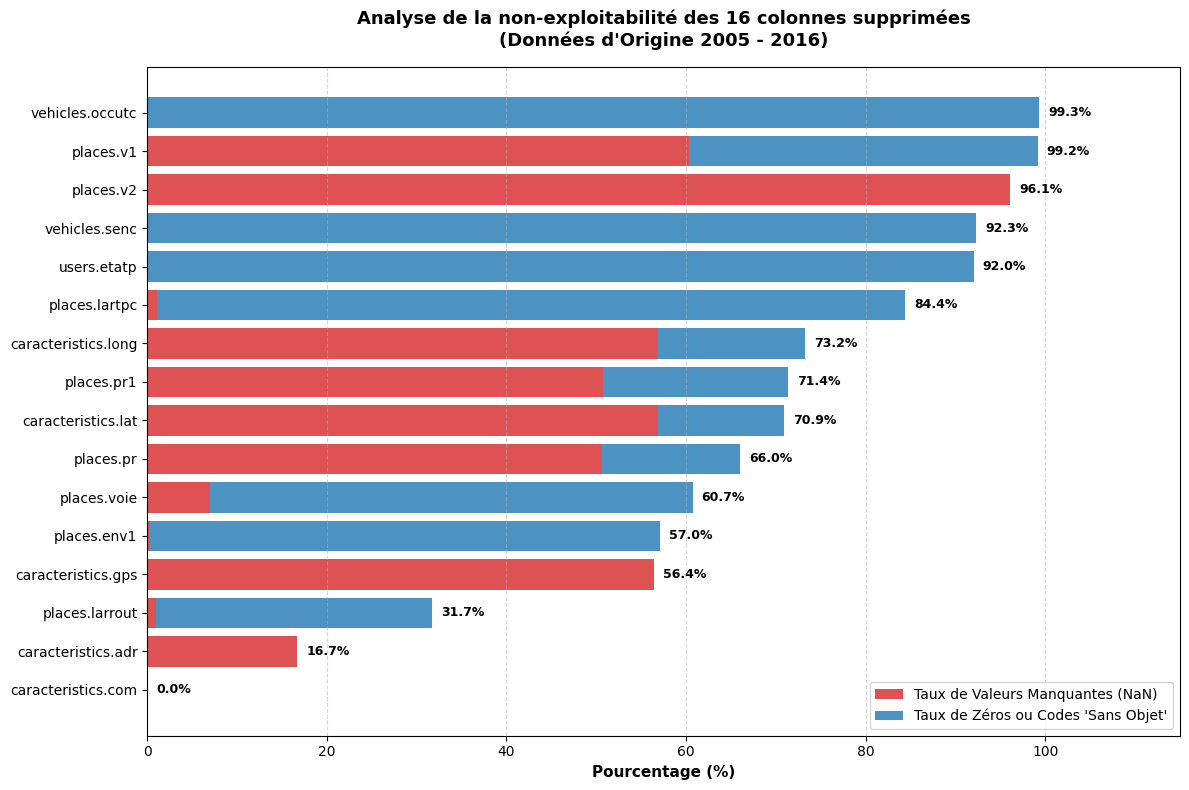

In [7]:
# Préparation des statistiques pour les 16 colonnes supprimées
stats_suppression = []

# Nous calculons dynamiquement sur les données d'origine
for table_name, cols in COLONNES_A_SUPPRIMER.items():
    df_origin = dataframes[table_name]
    n_rows = len(df_origin)

    for col in cols:
        # Taux de NaN réels
        pct_nan = df_origin[col].isna().mean() * 100

        # Calcul du taux de zéros numériques ou textuels ou code 'sans objet'
        # On cherche à capter les zéros ou valeurs par défaut non significatives
        zeros_count = 0
        if col in df_origin.columns:
            # Compte des zéros ou de la modalité la plus fréquente de non-réponse (0 ou 0.0)
            zeros_count = ((df_origin[col] == 0) | (df_origin[col] == 0.0) | (df_origin[col] == '0')).sum()

        pct_zeros = (zeros_count / n_rows) * 100

        # Taux cumulé d'inutilisabilité (NaN + Zéros/Sans objet)
        pct_total_inutile = min(100.0, pct_nan + pct_zeros)

        stats_suppression.append({
            'colonne': f"{table_name}.{col}",
            'pct_nan': pct_nan,
            'pct_zeros': pct_zeros,
            'pct_inutile': pct_total_inutile
        })

# Tri par taux cumulé d'inutilisabilité pour une meilleure lisibilité graphique
stats_suppression = sorted(stats_suppression, key=lambda x: x['pct_inutile'], reverse=False)

colonnes_names = [item['colonne'] for item in stats_suppression]
pct_nan_vals = [item['pct_nan'] for item in stats_suppression]
pct_zeros_vals = [item['pct_zeros'] for item in stats_suppression]

# Construction du graphique à barres empilées
_, ax = plt.subplots(figsize=(12, 8))

# Barres pour le taux de NaN
ax.barh(colonnes_names, pct_nan_vals, color='#d62728', alpha=0.8, label='Taux de Valeurs Manquantes (NaN)')
# Barres pour le taux de Zéros / Sans objet
ax.barh(colonnes_names, pct_zeros_vals, left=pct_nan_vals, color='#1f77b4', alpha=0.8, label='Taux de Zéros ou Codes \'Sans Objet\'')

# Esthétique générale
ax.set_xlim(0, 115) # Marge à droite pour afficher les étiquettes de texte
ax.set_xlabel('Pourcentage (%)', fontsize=11, fontweight='bold')
ax.set_title('Analyse de la non-exploitabilité des 16 colonnes supprimées\n(Données d\'Origine 2005 - 2016)', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, fontsize=10)

# Ajout des valeurs au bout de chaque barre
for i, item in enumerate(stats_suppression):
    total_pct = item['pct_inutile']
    ax.text(total_pct + 1, i, f"{total_pct:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## Conclusion et perspectives

### Bilan de l'étape 1
Nous avons écarté **16 variables** jugées inexploitables ou superflues à ce stade du projet :
- **5** issues de `caracteristics` (`com`, `adr`, `gps`, `lat`, `long`)
- **8** issues de `places` (`voie`, `v1`, `v2`, `pr`, `pr1`, `lartpc`, `larrout`, `env1`)
- **2** issues de `vehicles` (`senc`, `occutc`)
- **1** issue de `users` (`etatp`)

Toutes les clés primaires, temporelles et cibles (`Num_Acc`, `num_veh`, `an`, `dep`, `grav`) ont été rigoureusement protégées et conservées.

### Limites méthodologiques induites
Il convient de noter une conséquence directe de cette étape : la qualité de la couverture GPS spatiale historique (qui évoluait de 14 % en 2005 à 69 % en 2016) ne pourra plus servir de critère pour la sélection de notre année de travail, puisque nous avons supprimé les colonnes `lat`, `long` et `gps`. Néanmoins, notre capacité d'analyse spatiale n'est pas compromise car nous conservons la variable de département géographique (`dep`), parfaitement documentée et complète sur l'ensemble de la période historique.

## Étape 2 : Analyse approfondie de la qualité des données et de la cible au cours du temps

### 1. Pourquoi cette étape et pourquoi il faut faire attention aux zéros ?

L'objectif de cette section est de quantifier, pour chaque fichier et chaque année de la période historique (2005 - 2016), le taux d'information réellement manquante afin d'évaluer la qualité et la fiabilité temporelle de notre base de données.

Une analyse naïve se basant uniquement sur les valeurs `NaN` visibles conclurait à un taux de manquants extrêmement faible (généralement inférieur à 1 %). Cependant, le format BAAC utilise abondamment le code numérique `0` ou `0.0` comme valeur par défaut, ce qui cache plusieurs réalités bien distinctes :

- **(a) "Non renseigné" / Inconnu** : Il s'agit d'une véritable information manquante déguisée (ex. motif de déplacement inconnu).
- **(b) "Aucun" ou "Sans objet"** : Il s'agit d'une modalité parfaitement valide et informative (ex. absence d'infrastructure particulière au lieu de l'accident).
- **(c) "Sans objet pour cet usager"** : Une modalité qui est structurellement invalide pour certains profils d'usagers mais logique pour d'autres (ex. les actions et localisations d'un piéton pour un conducteur de voiture).

Remplacer aveuglément tous les `0` par des `NaN` fausserait gravement nos statistiques. Par exemple, la variable d'aménagement `infra` vaut `0` pour près de 89 % des lignes de façon très stable ; cela signifie simplement qu'il n'y a *aucun* aménagement spécifique (pont, tunnel, etc.), ce qui est une information cruciale.

Le code `0` n'étant pas explicitement documenté pour toutes les colonnes sur la plateforme Kaggle, nous avons formulé des **hypothèses d'interprétation du code 0 (à appliquer au prétraitement)**, fondées sur des constats préliminaires du dataset historique :

Dans cette étape, seule la règle A est appliquée au calcul de l'indicateur de manquants ; les règles B, C et D seront mises en oeuvre au prétraitement.

---

### 2. Hypothèses d'interprétation du code 0

#### RÈGLE A : Le code 0 équivaut à un "Non renseigné" (Manquant effectif)
Pour ces variables, toute valeur égale à `0` ou `0.0` (en plus des `NaN` classiques) est considérée comme une donnée manquante réelle :
- `caracteristics_1` : `int` (type d'intersection, part de zéros négligeable entre 0 % et 0,1 %).
- `places_1` : `circ` (régime de circulation), `prof` (pente), `plan` (tracé), `surf` (état de surface), `nbv` (nombre de voies : 0 voie de circulation étant physiquement impossible).
- `vehicles_1` : `manv` (manœuvre principale avant l'accident, où le code 0 correspond à "inconnue").
- `users_1` : `trajet` (motif du déplacement, où le code 0 signifie "non renseigné", représentant 25 à 36 % des observations selon les années).

* **Constat préliminaire (cooccurrence des zéros)** : Les zéros de `circ`, `prof`, `plan` et `surf` surviennent de manière groupée sur les mêmes lignes d'accidents beaucoup plus fréquemment que ne le voudrait le hasard. En effet, la proportion de cas où ces quatre variables valent simultanément `0` est d'environ **0,6 %**, alors que si elles étaient indépendantes, la probabilité théorique de cooccurrence aléatoire serait de l'ordre de **0,001 %**. Cela suggère qu'un non-renseignement traduit une omission globale de saisie de la fiche d'accident, et va dans le sens d'une donnée manquante pour le code 0 de ces colonnes ; ce constat sera à recalculer et à confirmer au prétraitement.

#### RÈGLE B : Le code 0 est une vraie modalité valide "Aucun / Sans objet" (Pas un manquant)
Pour ces colonnes, seuls les `NaN` réels sont comptabilisés comme manquants. Le code `0` est conservé tel quel :
- `places_1` : `infra` (0 = aucun aménagement particulier, ~89 % stable), `vosp` (0 = pas de voie réservée, ~93 à 95 %).
- `vehicles_1` : `obs` (0 = aucun obstacle fixe heurté, ~87 %), `obsm` (0 = aucun obstacle mobile heurté, ~19 à 24 %).

* **Constat préliminaire** : Les proportions associées à ces codes `0` sont extrêmement massives, stables au cours des années et totalement cohérentes avec les distributions attendues d'accidents en conditions physiques standard.

#### RÈGLE C : Cas ambigus (Double comptabilisation "Borne Basse" vs "Borne Haute")
Certaines variables présentent une ambiguïté structurelle où le `0` peut désigner à la fois une absence et un défaut de saisie. Nous présentons deux taux :
- `places_1` : `situ` (la documentation ONISR indique 0 = "aucun", mais la proportion de zéros double sur la période historique, passant de ~4 % en 2005 à ~8 % en 2016, ce qui suggère un biais de non-renseignement croissant).
- `vehicles_1` : `choc` (0 = "aucun choc" selon la notice, mais seulement 46 % des véhicules codés `choc = 0` n'ont effectivement heurté aucun obstacle fixe ou mobile. De plus, sa proportion augmente régulièrement de 5 % à 9 %).

#### RÈGLE D : Conditionnelle au statut de l'usager
Pour la table `users_1`, l'évaluation du taux de données manquantes s'effectue en segmentant la population selon le filtre `pieton = users_1['catu'].isin([3, 4])` :
- `locp` (localisation du piéton) & `actp` (action du piéton) : La valeur `0` signifie "sans objet" pour 99,9 % des non-piétons, ce qui est structurellement normal. Le manque d'information réel n'est donc mesuré **que sur le sous-ensemble des piétons** (où l'on observe ~10,7 % de zéros pour `locp` et ~5,1 % pour `actp`).
- `place` : Un piéton n'occupe aucune place dans un véhicule. De 2005 à 2008, 100 % des piétons sont codés `0` ; à partir de 2009, ils sont systématiquement codés `NaN`. Pour les non-piétons, la variable est complète à près de 99,7 %. Le taux de manque réel pour `place` doit donc être mesuré **uniquement sur le sous-ensemble des non-piétons**.
- `secu` (équipement de sécurité) : Un changement majeur de codage est intervenu en 2009 (passage d'un encodage à 1 chiffre à un encodage à 2 chiffres). Pour les piétons, la variable vaut `0` à 99,9 % entre 2005 et 2008, puis affiche de fortes proportions de `NaN` (33 % de 2009 à 2014, grimpant à 67 % en 2015 et 78 % en 2016 car la saisie s'est réorientée vers le caractère

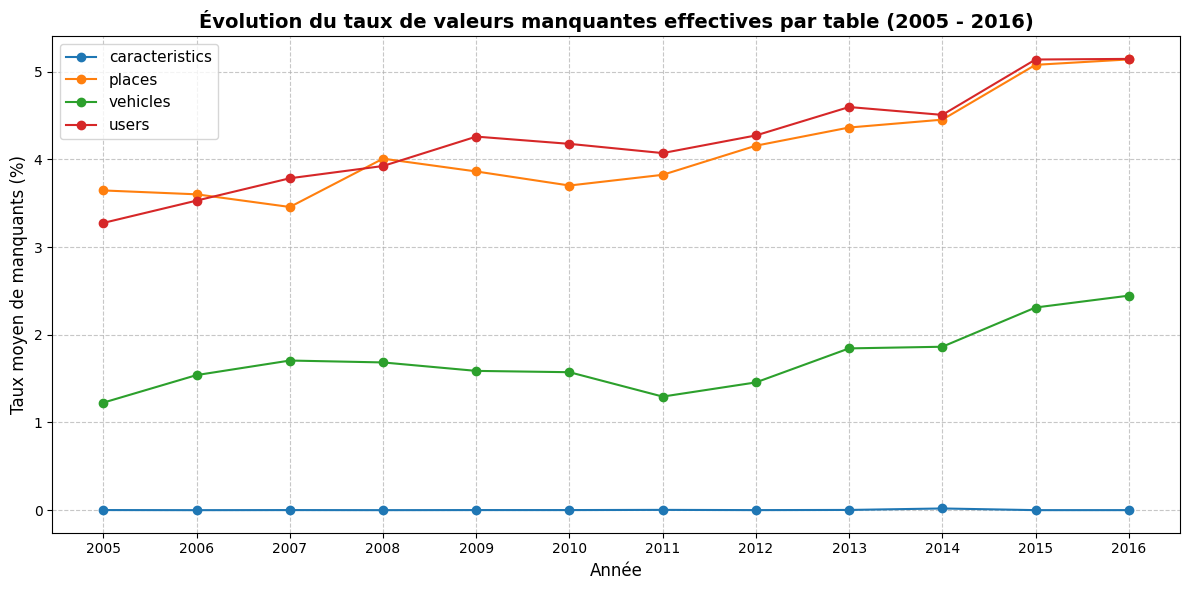

In [8]:
# 1. Construction de la Series pour mapper l'année à partir de caract_1
an_par_accident = caract_1.set_index('Num_Acc')['an']

# Dictionnaire des colonnes où 0 signifie 'valeur manquante'
COLS_ZERO_IS_MISSING = {
    'caracteristics': ['int'],
    'places': ['circ', 'prof', 'plan', 'surf', 'nbv'],
    'vehicles': ['manv'],
    'users': ['trajet']
}

# Calcul de l'évolution des données manquantes effectives par table
years_range = sorted(caract_1['an'].unique())
years_labels = [2000 + y for y in years_range]

missing_stats = {name: [] for name in ['caracteristics', 'places', 'vehicles', 'users']}

for y in years_range:
    # Filtre caract_1 pour l'année
    idx_caract = caract_1['an'] == y
    accidents_this_year = caract_1.loc[idx_caract, 'Num_Acc']

    # Table caracteristics
    sub_caract = caract_1.loc[idx_caract].drop(columns=['Num_Acc', 'an'])
    for col in COLS_ZERO_IS_MISSING['caracteristics']:
        if col in sub_caract.columns:
            sub_caract[col] = sub_caract[col].replace(0, np.nan)
    missing_stats['caracteristics'].append(sub_caract.isna().mean().mean() * 100)

    # Table places
    sub_places = places_1[places_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc'])
    for col in COLS_ZERO_IS_MISSING['places']:
        if col in sub_places.columns:
            sub_places[col] = sub_places[col].replace(0, np.nan)
    missing_stats['places'].append(sub_places.isna().mean().mean() * 100)

    # Table vehicles
    sub_veh = vehicles_1[vehicles_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc', 'num_veh'])
    for col in COLS_ZERO_IS_MISSING['vehicles']:
        if col in sub_veh.columns:
            sub_veh[col] = sub_veh[col].replace(0, np.nan)
    missing_stats['vehicles'].append(sub_veh.isna().mean().mean() * 100)

    # Table users
    sub_users = users_1[users_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc', 'num_veh'])
    for col in COLS_ZERO_IS_MISSING['users']:
        if col in sub_users.columns:
            sub_users[col] = sub_users[col].replace(0, np.nan)
    missing_stats['users'].append(sub_users.isna().mean().mean() * 100)

# Tracé des courbes de données manquantes par dataset au cours du temps
plt.figure(figsize=(12, 6))
for name, vals in missing_stats.items():
    plt.plot(years_labels, vals, marker='o', label=name)

plt.title("Évolution du taux de valeurs manquantes effectives par table (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Taux moyen de manquants (%)", fontsize=12)
plt.xticks(years_labels)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Répartition de la gravité par usager (2005-2016)

Cette répartition est par usager : en 2005, 23,5 % des usagers sont tués ou hospitalisés. Au niveau accident (au moins un usager grave), la part est de 43,95 %, car un accident compte en moyenne 2,27 usagers.

grav_label,1. Indemne,4. Blessé léger,3. Blessé hospitalisé,2. Tué
2005,40.64,35.89,20.65,2.81
2006,40.71,34.27,22.38,2.64
2007,40.81,35.53,21.09,2.57
2008,40.72,35.52,21.16,2.60
2009,40.86,35.68,20.79,2.68
2010,40.76,36.21,20.32,2.71
2011,40.77,35.84,20.62,2.77
2012,40.81,36.14,20.28,2.77
2013,40.89,35.55,20.90,2.66
2014,40.46,36.04,20.81,2.69


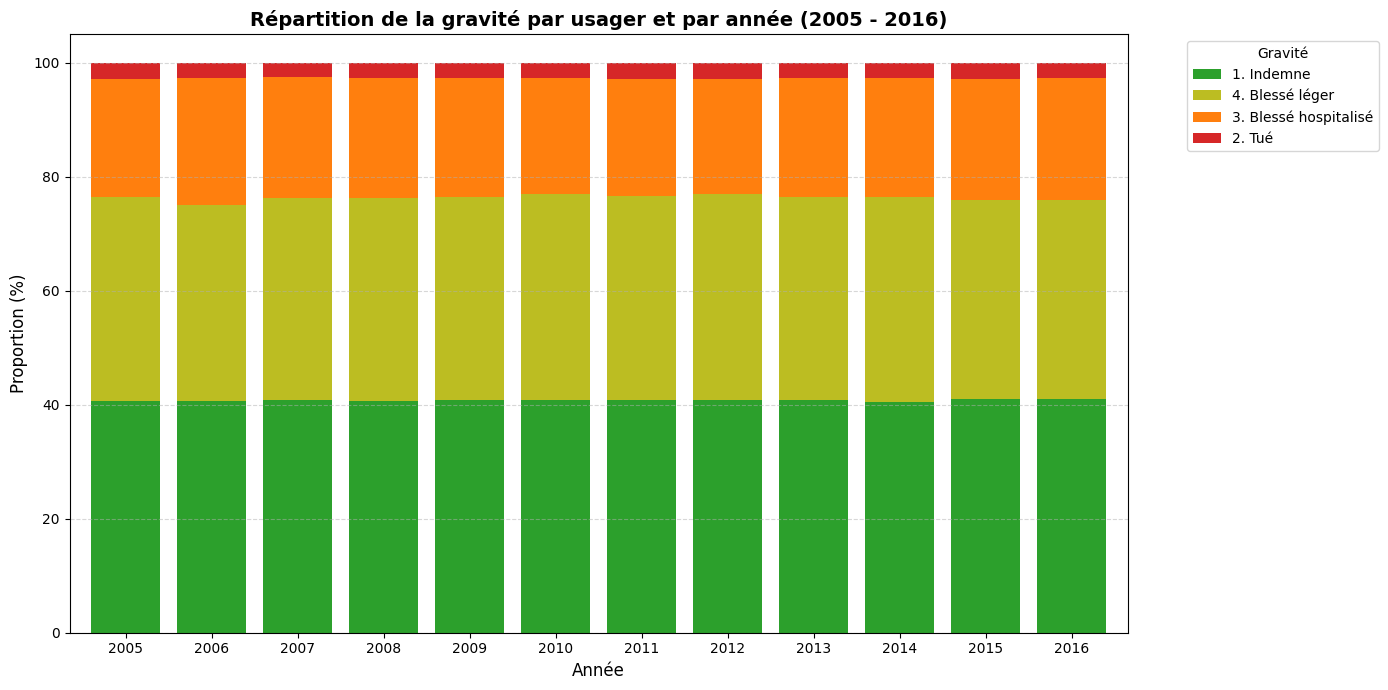

In [9]:
# Ajout de l'année à la table users_1 pour le regroupement
users_grav = users_1.copy()
users_grav['an'] = users_grav['Num_Acc'].map(an_par_accident)

# Mapping des libellés de gravité
grav_map = {
    1: "1. Indemne",
    2: "2. Tué",
    3: "3. Blessé hospitalisé",
    4: "4. Blessé léger"
}
users_grav['grav_label'] = users_grav['grav'].map(grav_map)

# Calcul de la table croisée normalisée
grav_pivot = pd.crosstab(users_grav['an'], users_grav['grav_label'], normalize='index') * 100
grav_pivot.index = [2000 + y for y in grav_pivot.index]

# Réorganisation des colonnes
ordered_cols = ["1. Indemne", "4. Blessé léger", "3. Blessé hospitalisé", "2. Tué"]
grav_pivot = grav_pivot[ordered_cols]

# Affichage de la table croisée
display(grav_pivot.round(2))

# Tracé du graphique en barres empilées à 100%
_, ax = plt.subplots(figsize=(14, 7))
grav_pivot.plot(kind='bar', stacked=True, color=['#2ca02c', '#bcbd22', '#ff7f0e', '#d62728'], ax=ax, width=0.8)

plt.title("Répartition de la gravité par usager et par année (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Proportion (%)", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Gravité", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Évolution des volumes de données par année (2005 - 2016)

Pour valider définitivement la robustesse de notre base historique, nous analysons l'évolution du nombre de lignes (observations) enregistrées chaque année dans nos quatre fichiers principaux de travail.

Tableau récapitulatif du nombre de lignes par année et par table :


,caracteristics_1,places_1,vehicles_1,users_1
Année,,,,
2005,"87,026","87,026","149,764","197,498"
2006,"82,993","82,993","142,300","187,085"
2007,"83,850","83,850","144,130","188,457"
2008,"76,767","76,767","131,048","170,960"
2009,"74,409","74,409","126,347","165,962"
2010,"69,379","69,379","117,743","154,192"
2011,"66,974","66,974","113,854","148,543"
2012,"62,250","62,250","105,814","138,628"
2013,"58,397","58,397","98,925","128,694"


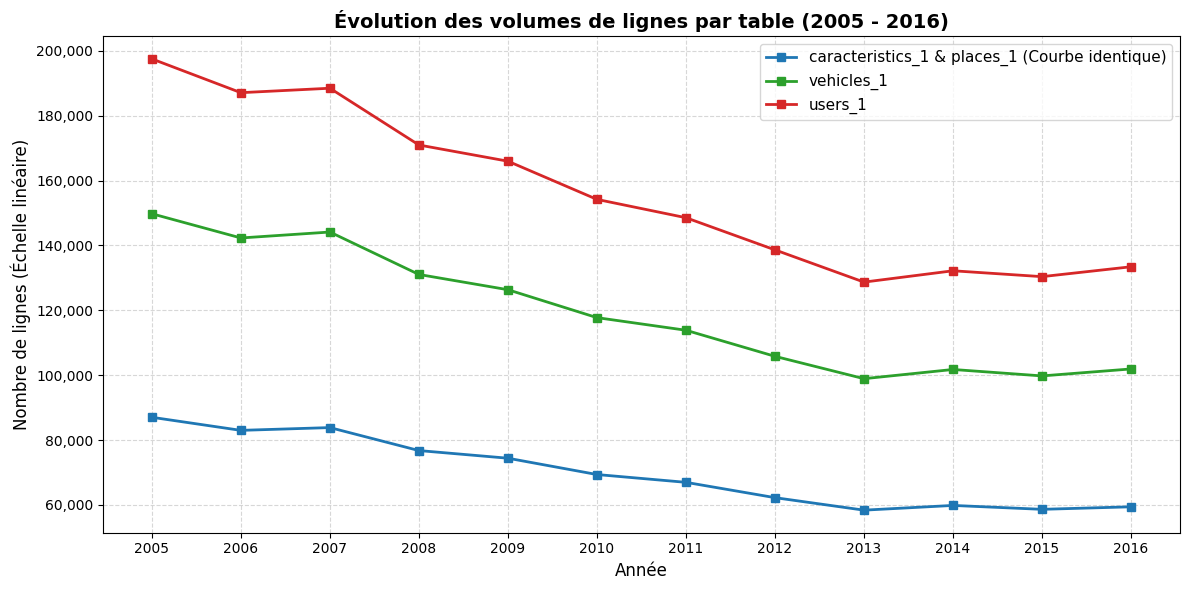

In [10]:
# Extraction des volumes par année en utilisant la série temporelle construite précédemment
years_list = sorted(caract_1['an'].unique())
years_labels = [2000 + y for y in years_list]

volumes = {
    'caracteristics_1': [],
    'places_1': [],
    'vehicles_1': [],
    'users_1': []
}

for y in years_list:
    # Filtre des identifiants d'accidents pour l'année en cours
    acc_year = caract_1.loc[caract_1['an'] == y, 'Num_Acc']

    volumes['caracteristics_1'].append(len(acc_year))
    volumes['places_1'].append(places_1['Num_Acc'].isin(acc_year).sum())
    volumes['vehicles_1'].append(vehicles_1['Num_Acc'].isin(acc_year).sum())
    volumes['users_1'].append(users_1['Num_Acc'].isin(acc_year).sum())

# Conversion en DataFrame pour affichage
df_volumes = pd.DataFrame(volumes, index=years_labels)
df_volumes.index.name = 'Année'

print("Tableau récapitulatif du nombre de lignes par année et par table :")
display(df_volumes.style.format("{:,}"))

# Tracé des courbes d'évolution des volumes
plt.figure(figsize=(12, 6))

# Comme caracteristics_1 et places_1 ont exactement le même nombre de lignes (1 ligne par accident),
# nous ne traçons qu'une seule courbe pour représenter les deux tables et l'indiquons clairement dans la légende.
plt.plot(df_volumes.index, df_volumes['caracteristics_1'], marker='s', linewidth=2,
         color='#1f77b4', label='caracteristics_1 & places_1 (Courbe identique)')

plt.plot(df_volumes.index, df_volumes['vehicles_1'], marker='s', linewidth=2,
         color='#2ca02c', label='vehicles_1')

plt.plot(df_volumes.index, df_volumes['users_1'], marker='s', linewidth=2,
         color='#d62728', label='users_1')

plt.title("Évolution des volumes de lignes par table (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Nombre de lignes (Échelle linéaire)", fontsize=12)
plt.xticks(years_labels)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

### Conclusion sur le choix de l'année d'étude

À la lumière des analyses temporelles approfondies menées sur la période historique (2005 - 2016), nous choisissons de retenir exclusivement l'année **2005** pour la construction de notre jeu de données final de modélisation. Ce choix stratégique repose sur trois arguments principaux :

1. **Maximisation de la volumétrie (Nombre de lignes)** :
   Comme le montre le graphique d'évolution temporelle des volumes, l'année 2005 présente le niveau d'activité historique le plus élevé avec **87 026 accidents individuels** enregistrés.

2. **Qualité des données (critère secondaire)** :
   Selon l'indicateur simple du graphique « Évolution du taux de valeurs manquantes effectives par table » ci-dessus (NaN + zéros de la règle A), 2005 présente le taux de manquants le plus bas pour users et vehicles, et l'un des plus bas pour places. Cet indicateur reste provisoire : place et secu sont codées 0 en 2005-2008 puis NaN, ce qui avantage ces années ; l'interprétation fine des zéros (règles C et D) sera traitée au prétraitement. Les écarts entre années restent de quelques points : la qualité n'est donc pas le critère principal du choix.

3. **Stabilité de la distribution de la variable cible `grav`** :
   La part d'accidents graves varie seulement de 42,7 % à 45,7 % selon les années (43,95 % en 2005), et la répartition de grav par usager est stable. Travailler sur une seule année ne modifie donc pas matériellement l'équilibre de la variable à prédire. Ce constat justifie de se limiter à une année ; le choix de 2005 repose sur le volume (87 026 accidents, le maximum de la période).

**Limites méthodologiques** :
L'utilisation exclusive de l'année 2005 implique certaines limites historiques : les données sont anciennes, les variables `place` et `secu` possèdent un codage spécifique propre à la période 2005-2008, et la transférabilité de nos modèles prédictifs aux années récentes devra faire l'objet de vérifications ultérieures.

## Étape 3 : Construction de la cible au niveau accident (année 2005)

### Définition de la variable cible de gravité au niveau de l'accident

Dans le cadre de notre modélisation, nous cherchons à prédire la gravité globale d'un accident. Pour ce faire, nous définissons une variable cible binaire `accident_grave` :
- **Grave (1)** : Si l'accident implique au moins un usager tué (code `2`) ou hospitalisé (code `3`).
- **Bénin (0)** : Si l'accident n'implique que des usagers indemnes (code `1`) ou des blessés légers (code `4`).

La gravité est ainsi agrégée à l'échelle de l'événement unique (l'accident) en prenant le maximum de gravité constaté parmi l'ensemble des usagers impliqués.

### 1. Extraction et isolation des données strictes pour l'année 2005

In [11]:
# Identification des accidents de 2005
accidents_2005_ids = caract_1[caract_1['an'] == 5]['Num_Acc'].unique()

# Filtrage de chaque table pour ne garder que l'année 2005
caract_2005 = caract_1[caract_1['Num_Acc'].isin(accidents_2005_ids)].copy()
places_2005 = places_1[places_1['Num_Acc'].isin(accidents_2005_ids)].copy()
vehicles_2005 = vehicles_1[vehicles_1['Num_Acc'].isin(accidents_2005_ids)].copy()
users_2005 = users_1[users_1['Num_Acc'].isin(accidents_2005_ids)].copy()

print(f"-> accidents_2005 : {caract_2005.shape[0]:,} accidents")
print(f"-> places_2005        : {places_2005.shape[0]:,} lignes")
print(f"-> vehicles_2005      : {vehicles_2005.shape[0]:,} lignes")
print(f"-> users_2005         : {users_2005.shape[0]:,} lignes")

-> accidents_2005 : 87,026 accidents
-> places_2005        : 87,026 lignes
-> vehicles_2005      : 149,764 lignes
-> users_2005         : 197,498 lignes


### 2. Définition de la variable cible de gravité à la maille accident et analyse de sa répartition

In [12]:
# Agrégation de la gravité maximale par accident
accidents_gravite = (users_2005['grav'].isin([2, 3]).groupby(users_2005['Num_Acc']).max().astype(int).rename('accident_grave').reset_index())

# Calcul des proportions
classes_count = accidents_gravite['accident_grave'].value_counts()
prop_benin = (classes_count[0] / len(accidents_gravite)) * 100
prop_grave = (classes_count[1] / len(accidents_gravite)) * 100

print("Distribution de la cible 'accident_grave' pour l'année d'étude 2005 :")
print(f" -> Accidents Bénins (Classe 0) : {classes_count[0]:,} ({prop_benin:.2f}%)")
print(f" -> Accidents Graves (Classe 1) : {classes_count[1]:,} ({prop_grave:.2f}%)")

Distribution de la cible 'accident_grave' pour l'année d'étude 2005 :
 -> Accidents Bénins (Classe 0) : 48,782 (56.05%)
 -> Accidents Graves (Classe 1) : 38,244 (43.95%)


### 3. Visualisation graphique de la répartition de la variable cible

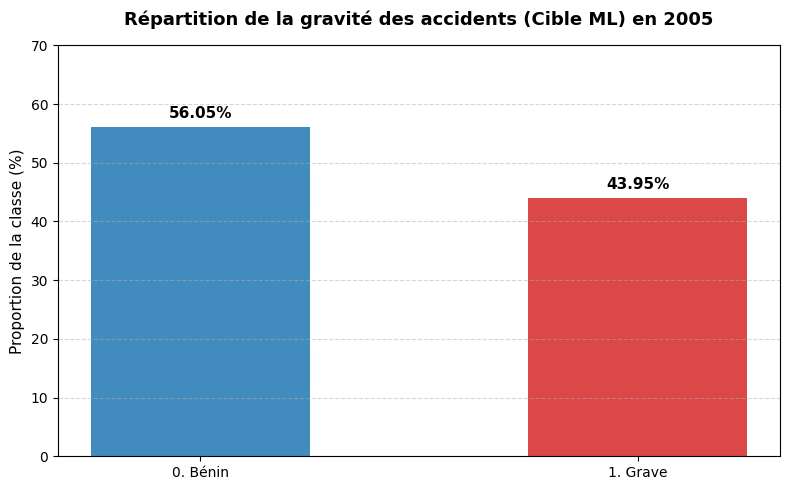

In [13]:
# Création d'un graphique à barres pour visualiser le ratio de distribution
plt.figure(figsize=(8, 5))
colors = ['#1f77b4', '#d62728']
plt.bar(['0. Bénin', '1. Grave'], [prop_benin, prop_grave], color=colors, alpha=0.85, width=0.5)

# Ajout des étiquettes de pourcentage sur les barres
for i, val in enumerate([prop_benin, prop_grave]):
    plt.text(i, val + 1, f"{val:.2f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title("Répartition de la gravité des accidents (Cible ML) en 2005", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Proportion de la classe (%)", fontsize=11)
plt.ylim(0, 70)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 4. Conclusion sur l'équilibre du dataset

La visualisation de la répartition montre que le jeu de données d'accidents corporels de l'année 2005 présente une proportion de **43,95 % d'accidents graves** contre **56,05 % d'accidents bénins**.

Ce ratio est très proche d'un équilibre parfait (50/50) pour des algorithmes de Machine Learning supervisés. En effet, il ne s'agit pas d'un problème de classe rare ou très déséquilibrée.

**Décision méthodologique** :
Compte tenu de cette répartition que nous jugeons saine, **nous décidons de conserver l'intégralité des 87 026 accidents de l'année 2005** sans procéder à aucun sous-échantillonnage, sur-échantillonnage ou rééquilibrage artificiel.
Cela offre de multiples avantages :
- Nous préservons la totalité de l'information et des données à notre disposition pour optimiser la phase d'apprentissage.
- Nous évitons de biaiser la réalité statistique des caractéristiques de l'année 2005.
- L'impact d'un déséquilibre aussi minime sur les métriques de notre modèle de Machine Learning sera négligeable.

### 5. Ajout de la cible et bilan des volumes

In [14]:
# Ajout de la cible de gravité de l'accident directement sur la table caractéristiques
accidents_target_map = dict(zip(accidents_gravite['Num_Acc'], accidents_gravite['accident_grave']))
caract_2005['target_grave'] = caract_2005['Num_Acc'].map(accidents_target_map)

print("Bilan final des volumes synchronisés pour l'étape suivante :")
print(f" -> caract_2005 : {caract_2005.shape[0]:,} accidents")
print(f" -> places_2005 : {places_2005.shape[0]:,} lignes")
print(f" -> vehicles_2005 : {vehicles_2005.shape[0]:,} véhicules")
print(f" -> users_2005    : {users_2005.shape[0]:,} usagers")

Bilan final des volumes synchronisés pour l'étape suivante :
 -> caract_2005 : 87,026 accidents
 -> places_2005 : 87,026 lignes
 -> vehicles_2005 : 149,764 véhicules
 -> users_2005    : 197,498 usagers


# Étape 4 : Feature engineering - construction du jeu de données (une ligne par accident)

### Principe et objectif
Notre objectif est de prédire la gravité d'un accident. L'unité d'analyse retenue à l'étape 3 est donc l'**accident** : le jeu de modélisation doit contenir **une ligne par accident** (une ligne = un accident de 2005) avec la variable cible `target_grave`.

Les tables n'ont pas la même granularité :

| Table | Une ligne représente | Relation avec l'accident | Traitement |
|---|---|---|---|
| `caract_2005` | un accident | 1-1 | jointure directe |
| `places_2005` | un accident (la route) | 1-1 | jointure directe |
| `vehicles_2005` | un véhicule | 1-n (plusieurs véhicules par accident) | **agrégation** par `Num_Acc` |
| `users_2005` | un usager | 1-n (plusieurs usagers par accident) | **agrégation** par `Num_Acc` |

**Pourquoi agréger plutôt que joindre directement ?** Joindre `vehicles` ou `users` tels quels dupliquerait chaque accident autant de fois qu'il compte de véhicules ou d'usagers. Les proportions de classes seraient faussées, et un même accident pourrait se retrouver à la fois dans l'entraînement et dans le test (fuite de données). L'agrégation résume, pour chaque accident, l'information de ses véhicules et de ses usagers.

### Variables construites

| Variable | Origine | Définition |
|---|---|---|
| `type_jour` | `caracteristics` + `holidays` | `ferie`, `week_end` ou `jour_ordinaire` |
| `moment_journee` | `caracteristics` (heure) | `nuit` (22h-5h59), `matin` (6h-11h59), `journee` (12h-17h59), `soir` (18h-21h59) |
| `categorie_age` | `users` (année de naissance) | classe d'âge du plus jeune usager de l'accident : `moins_18`, `18_24`, `25_49`, `50_64`, `65_plus`, `inconnu` |
| `usager_sans_protection` | `users` (équipement de sécurité) | 1 si au moins un usager équipé n'a pas porté sa ceinture ou son casque, 0 sinon |
| `nb_velo`, `nb_deux_roues_motorise`, `nb_voiture`, `nb_utilitaire`, `nb_poids_lourd`, `nb_transport_commun`, `nb_engin`, `nb_autre` | `vehicles` (catégorie de véhicule) | nombre de véhicules de chaque type impliqués dans l'accident |

### Précautions contre la fuite de données
- Chaque variable est calculée **uniquement à partir des lignes de l'accident lui-même**, avec des règles fixées à l'avance (seuils, codes). Elles ne dépendent pas des autres accidents : elles peuvent donc être créées **avant** le découpage entraînement / validation / test sans fuite.
- La gravité individuelle `grav` n'est **jamais** utilisée pour construire une variable explicative : c'est la source de la cible.
- Tout ce qui apprend à partir des données (imputation, normalisation, encodage dépendant de la cible, rééquilibrage) sera fait **après** le découpage, sur l'entraînement uniquement, dans des pipelines.
- Les autres colonnes de `vehicles` et `users` (obstacle heurté, point de choc, manoeuvre, sexe, motif du trajet, etc.) ne sont pas agrégées pour l'instant. Elles le seront dans l'étape suivante.

### 4.1 Jointure des tables à relation 1-1 (`caract_2005` et `places_2005`)
`caract_2005` (qui contient déjà la cible `target_grave`) et `places_2005` ont chacune une ligne par accident. On les joint sur `Num_Acc` avec `validate='one_to_one'` : pandas lève une erreur si une clé était dupliquée, ce qui garantit qu'aucun accident n'est multiplié.

In [15]:
# Jointure 1-1 : caracteristics (avec la cible) + places, sur l'identifiant de l'accident
df_accidents = caract_2005.merge(places_2005, on='Num_Acc', how='left', validate='one_to_one')

# Contrôles : aucun accident perdu ni dupliqué, et chaque accident a bien sa ligne 'places'
assert len(df_accidents) == len(caract_2005)
assert df_accidents['Num_Acc'].is_unique
assert caract_2005['Num_Acc'].isin(places_2005['Num_Acc']).all()
print("Tous les accidents de caract_2005 ont une ligne correspondante dans places_2005.")
print(f"df_accidents après jointure 1-1 : {df_accidents.shape[0]:,} lignes x {df_accidents.shape[1]} colonnes")

Tous les accidents de caract_2005 ont une ligne correspondante dans places_2005.
df_accidents après jointure 1-1 : 87,026 lignes x 21 colonnes


### 4.2 Variables temporelles : type de jour et moment de la journée

**Type de jour (3 modalités).** On croise la date de l'accident avec `holidays_1` pour obtenir une variable à trois valeurs : `ferie`, `week_end` ou `jour_ordinaire`. Les conditions de circulation diffèrent selon ces jours (trafic de loisirs, retours de week-end, comportements à risque). *Règle de priorité* : un jour férié qui tombe un week-end est classé `ferie`, pour que cette modalité regroupe tous les jours fériés.

**Moment de la journée (4 modalités).** L'heure exacte (`hrmn`, au format HHMM) est trop fine pour un modèle. On la regroupe en quatre plages : `nuit` (22h-5h59), `matin` (6h-11h59), `journee` (12h-17h59) et `soir` (18h-21h59). Ces bornes sont fixées à l'avance et ne dépendent pas des données. À noter : `moment_journee` est corrélée à l'éclairage (`lum`), mais elle décrit le moment de la journée et non la visibilité sur la route ; nous gardons les deux.

In [16]:
# --- Type de jour : férié / week-end / jour ordinaire ---
dates = pd.to_datetime(pd.DataFrame({
    'year': 2000 + df_accidents['an'],     # 'an' est sur 2 chiffres (5 = 2005)
    'month': df_accidents['mois'],
    'day': df_accidents['jour']
}))
assert dates.notna().all(), "Date invalide détectée"

jours_feries = set(pd.to_datetime(holidays_1['ds']).dt.normalize())
est_ferie = dates.isin(jours_feries)
est_weekend = dates.dt.dayofweek >= 5      # 5 = samedi, 6 = dimanche

df_accidents['type_jour'] = np.select([est_ferie, est_weekend], ['ferie', 'week_end'], default='jour_ordinaire')

# --- Moment de la journée : nuit / matin / journée / soir ---
heure = df_accidents['hrmn'] // 100        # hrmn au format HHMM (1445 = 14h45)
assert heure.between(0, 23).all(), "Heure invalide détectée"

df_accidents['moment_journee'] = np.select(
    [heure.between(6, 11), heure.between(12, 17), heure.between(18, 21)],
    ['matin', 'journee', 'soir'],
    default='nuit'                         # 22h-5h59
)

# Affichage immédiat des nouvelles colonnes temporelles
display(df_accidents[['Num_Acc', 'type_jour', 'moment_journee']].head())

print("\nRépartition de type_jour :")
print(df_accidents['type_jour'].value_counts())
print(f"\n -> dont jours fériés tombant un week-end (classés 'ferie') : {(est_ferie & est_weekend).sum():,}")
print("\nRépartition de moment_journee :")
print(df_accidents['moment_journee'].value_counts())

,Num_Acc,type_jour,moment_journee
0,200500000001,jour_ordinaire,soir
1,200500000002,jour_ordinaire,journee
2,200500000003,jour_ordinaire,soir
3,200500000004,jour_ordinaire,journee
4,200500000005,jour_ordinaire,soir



Répartition de type_jour :
type_jour
jour_ordinaire    62889
week_end          22128
ferie              2009
Name: count, dtype: int64

 -> dont jours fériés tombant un week-end (classés 'ferie') : 738

Répartition de moment_journee :
moment_journee
journee    34080
matin      22305
soir       19793
nuit       10848
Name: count, dtype: int64


### 4.3 Agrégation des usagers : classe d'âge et usager sans protection

**Catégorie d'âge.** On calcule l'âge de chaque usager (`2005 - an_nais`, approximation à un an près car le mois de naissance est inconnu). Les âges impossibles (négatifs ou supérieurs à 100 ans) sont considérés comme manquants. Pour résumer l'accident en une seule valeur, on retient l'**âge du plus jeune usager** (conducteur, passager ou piéton), puis on le classe : `moins_18`, `18_24`, `25_49`, `50_64`, `65_plus`. Les seuils sont fixes (majorité, fin de la période de jeune conducteur, seniors à partir de 65 ans). Ce choix d'âge min détecte la présence d'enfants et de jeunes ; comme il porte sur tous les usagers, il laisse moins d'accidents sans âge connu qu'un choix limité aux conducteurs. Si aucun âge valide n'existe dans l'accident, la modalité est `inconnu`.

**Usager sans protection.** `secu` est un code à deux chiffres : le premier indique l'équipement (1 ceinture, 2 casque, 3 dispositif enfant, 4 gilet réfléchissant, 9 autre), le second son utilisation (1 oui, 2 non, 3 non déterminable). On crée un indicateur qui vaut 1 si au moins un usager a le code `12` (ceinture non portée) ou `22` (casque non porté). Les codes « non déterminable » (`13`, `23`) et les valeurs `0` ou manquantes ne sont pas comptés comme un défaut de protection, faute de preuve ; cela peut sous-estimer légèrement le phénomène.

In [17]:
ANNEE_ETUDE = 2005

# Âge de chaque usager (âges impossibles -> NaN)
age = ANNEE_ETUDE - users_2005['an_nais']
age = age.where(age.between(0, 100))

users_tmp = pd.DataFrame({
    'Num_Acc': users_2005['Num_Acc'],
    'age': age,
    'sans_protection': users_2005['secu'].isin([12, 22])   # ceinture (12) ou casque (22) équipé mais non porté
})

# Agrégation par accident : âge du plus jeune usager, et présence d'au moins un usager sans protection
users_agg = users_tmp.groupby('Num_Acc').agg(
    age_min=('age', 'min'),
    usager_sans_protection=('sans_protection', 'max')
).reset_index()

users_agg['categorie_age'] = pd.cut(
    users_agg['age_min'],
    bins=[-1, 17, 24, 49, 64, 100],
    labels=['moins_18', '18_24', '25_49', '50_64', '65_plus']
).astype(object).fillna('inconnu')
users_agg['usager_sans_protection'] = users_agg['usager_sans_protection'].astype(int)
users_agg = users_agg.drop(columns='age_min')

# Contrôles : une seule ligne par accident, aucun accident perdu
assert users_agg['Num_Acc'].is_unique
assert len(users_agg) == users_2005['Num_Acc'].nunique()

# Affichage immédiat des nouvelles colonnes usagers agrégées
display(users_agg[['Num_Acc', 'categorie_age', 'usager_sans_protection']].head())

print("\nRépartition de categorie_age :")
print(users_agg['categorie_age'].value_counts())
print("\nRépartition de usager_sans_protection :")
print(users_agg['usager_sans_protection'].value_counts())

,Num_Acc,categorie_age,usager_sans_protection
0,200500000001,moins_18,0
1,200500000002,25_49,0
2,200500000003,18_24,0
3,200500000004,25_49,0
4,200500000005,moins_18,0



Répartition de categorie_age :
categorie_age
25_49       37130
18_24       26776
moins_18    16162
50_64        5053
65_plus      1748
inconnu       157
Name: count, dtype: int64

Répartition de usager_sans_protection :
usager_sans_protection
0    81879
1     5147
Name: count, dtype: int64


### 4.4 Agrégation des véhicules : regroupement par type
La catégorie de véhicule `catv` compte une vingtaine de codes. On les regroupe en 8 types :

| Groupe | Codes `catv` |
|---|---|
| `velo` | 1 |
| `deux_roues_motorise` (cyclomoteur, moto, scooter, side-car) | 2, 4, 5, 6 |
| `voiture` | 3, 7, 8, 9 |
| `utilitaire` | 10, 11, 12 |
| `poids_lourd` | 13 à 17 |
| `transport_commun` | 18, 19 |
| `engin` (engins agricoles et spéciaux) | 20, 21 |
| `autre` | 99 |

Pour chaque accident, on compte le nombre de véhicules de chaque type (`nb_velo`, `nb_voiture`, etc.). Le comptage conserve plus d'information qu'une simple présence (un accident avec deux poids lourds se distingue d'un accident avec un seul), et la présence se retrouve par `nb_... > 0`.

In [18]:
CODES_PAR_GROUPE = {
    'velo': [1],
    'deux_roues_motorise': [2, 4, 5, 6],
    'voiture': [3, 7, 8, 9],
    'utilitaire': [10, 11, 12],
    'poids_lourd': [13, 14, 15, 16, 17],
    'transport_commun': [18, 19],
    'engin': [20, 21],
    'autre': [99],
}
GROUPE_PAR_CODE = {code: groupe for groupe, codes in CODES_PAR_GROUPE.items() for code in codes}

groupe_vehicule = vehicles_2005['catv'].map(GROUPE_PAR_CODE)
assert groupe_vehicule.notna().all(), f"Codes catv non reconnus : {sorted(vehicles_2005.loc[groupe_vehicule.isna(), 'catv'].unique())}"

# Nombre de véhicules de chaque type, par accident
vehicles_agg = (pd.crosstab(vehicles_2005['Num_Acc'], groupe_vehicule)
                  .reindex(columns=list(CODES_PAR_GROUPE), fill_value=0)
                  .add_prefix('nb_')
                  .reset_index())
vehicles_agg.columns.name = None

colonnes_nb = [c for c in vehicles_agg.columns if c.startswith('nb_')]

# Contrôles : une seule ligne par accident, aucun véhicule perdu
assert vehicles_agg['Num_Acc'].is_unique
assert vehicles_agg[colonnes_nb].sum().sum() == len(vehicles_2005)

# Affichage immédiat des nouvelles colonnes véhicules agrégées
display(vehicles_agg[['Num_Acc'] + colonnes_nb].head())

resume = pd.DataFrame({
    'véhicules': vehicles_agg[colonnes_nb].sum(),
    'accidents concernés': (vehicles_agg[colonnes_nb] > 0).sum()
})
resume['% des accidents'] = (resume['accidents concernés'] / len(vehicles_agg) * 100).round(1)
print("\nBilan par type de véhicule :")
display(resume)

,Num_Acc,nb_velo,nb_deux_roues_motorise,nb_voiture,nb_utilitaire,nb_poids_lourd,nb_transport_commun,nb_engin,nb_autre
0,200500000001,0,0,2,0,0,0,0,0
1,200500000002,0,1,1,0,0,0,0,0
2,200500000003,0,2,0,0,0,0,0,0
3,200500000004,0,0,3,0,0,0,0,0
4,200500000005,0,0,1,0,0,0,0,0



Bilan par type de véhicule :


,véhicules,accidents concernés,% des accidents
nb_velo,5213,5064,5.8
nb_deux_roues_motorise,33726,32587,37.4
nb_voiture,99439,72839,83.7
nb_utilitaire,3783,3604,4.1
nb_poids_lourd,4797,4474,5.1
nb_transport_commun,1505,1484,1.7
nb_engin,492,489,0.6
nb_autre,809,777,0.9


### 4.5 Assemblage du jeu final
On joint à `df_accidents` les deux tables agrégées (une ligne par accident chacune) avec `validate='one_to_one'`. Les comptages de véhicules manquants éventuels sont mis à 0 (aucun véhicule de ce type).

In [19]:
df_accidents = (df_accidents
                .merge(users_agg, on='Num_Acc', how='left', validate='one_to_one')
                .merge(vehicles_agg, on='Num_Acc', how='left', validate='one_to_one'))

df_accidents[colonnes_nb] = df_accidents[colonnes_nb].fillna(0).astype(int)

# Contrôles : aucun accident perdu ou dupliqué, aucune variable construite manquante
assert len(df_accidents) == len(caract_2005)
assert df_accidents['Num_Acc'].is_unique
assert df_accidents[['categorie_age', 'usager_sans_protection']].notna().all().all()
print(f"df_accidents après assemblage : {df_accidents.shape[0]:,} lignes x {df_accidents.shape[1]} colonnes")

df_accidents après assemblage : 87,026 lignes x 33 colonnes


### 4.6 Suppression des colonnes de date et d'heure
Les nouvelles variables `type_jour` et `moment_journee` contiennent désormais l'information utile de la date et de l'heure. On supprime donc les colonnes brutes :
- `mois`, `jour` et `hrmn` : valeurs très détaillées (366 jours, 1 440 minutes) qui pousseraient un modèle à mémoriser des cas particuliers sans généraliser ;
- `an` : constante (2005) pour toutes les lignes, elle n'apporte aucune information.

In [20]:
df_accidents = df_accidents.drop(columns=['an', 'mois', 'jour', 'hrmn'])
print(f"Colonnes supprimées : an, mois, jour, hrmn -> {df_accidents.shape[1]} colonnes restantes")

Colonnes supprimées : an, mois, jour, hrmn -> 29 colonnes restantes


### 4.7 Bilan du jeu de données construit
Contrôles finaux : une ligne par accident, la cible est présente et complète, et aucune colonne issue de la gravité individuelle `grav` n'est présente parmi les variables explicatives.

In [21]:
assert df_accidents['Num_Acc'].is_unique
assert 'grav' not in df_accidents.columns
assert df_accidents['target_grave'].notna().all()

print(f"Jeu final : {df_accidents.shape[0]:,} accidents x {df_accidents.shape[1]} colonnes")
print("\nDistribution de la cible :")
print(df_accidents['target_grave'].value_counts().rename({0: 'Bénins (0)', 1: 'Graves (1)'}))

bilan = pd.DataFrame({
    'type': df_accidents.dtypes.astype(str),
    'nb_manquants': df_accidents.isna().sum(),
    'nb_valeurs_distinctes': df_accidents.nunique()
})
display(bilan)

Jeu final : 87,026 accidents x 29 colonnes

Distribution de la cible :
target_grave
Bénins (0)    48782
Graves (1)    38244
Name: count, dtype: int64


,type,nb_manquants,nb_valeurs_distinctes
Num_Acc,int64,0,87026
lum,int64,0,5
agg,int64,0,2
int,int64,0,10
atm,float64,0,9
col,float64,0,7
dep,int64,0,100
target_grave,int64,0,2
catr,float64,1,7
circ,float64,0,5


### Conclusion de l’étape 4

Nous avons construit `df_accidents`, une table de **87 026 accidents corporels survenus en 2005**, avec **29 colonnes et une seule ligne par accident**. Elle rassemble les caractéristiques de l’accident et du lieu, la cible `target_grave` et les variables créées à partir du calendrier, des usagers et des véhicules.

Les nouvelles variables décrivent le type de jour, le moment de la journée, la classe d’âge de l’usager le plus jeune, la présence d’au moins un usager identifié comme ne portant pas sa ceinture ou son casque, et le nombre de véhicules par type. La classe d’âge repose sur une estimation à partir de l’année de naissance. Pour la protection, les cas non renseignés ou indéterminés ne sont pas comptés comme des absences de protection.

# Étape 5 — Enrichissement à partir des véhicules et des usagers

L’étape 4 a construit un jeu de données à une ligne par accident pour l’année 2005. Nous enrichissons ce jeu avec quatre variables issues des véhicules (`obs`, `obsm`, `choc`, `manv`) et quatre issues des usagers (`sexe`, `trajet`, `locp`, `actp`).

Nous commençons par examiner les codes observés. Pour `locp` et `actp`, les fréquences sont calculées uniquement parmi les piétons.

In [22]:
import pandas as pd
from IPython.display import display

cle = "Num_Acc"
colonnes_vehicules = ["obs", "obsm", "choc", "manv"]
colonnes_usagers = ["catu", "sexe", "trajet", "locp", "actp"]

vehicules_5 = vehicles_2005[[cle, *colonnes_vehicules]].copy()
usagers_5 = users_2005[[cle, *colonnes_usagers]].copy()

# Le code 3 désigne les piétons. Le code 4 couvre les piétons
# en roller ou en trottinette dans le dictionnaire utilisé.
est_pieton = pd.to_numeric(usagers_5["catu"], errors="coerce").isin([3, 4])

sources_audit = [
    (vehicules_5, colonnes_vehicules, "Véhicules"),
    (usagers_5, ["catu", "sexe", "trajet"], "Usagers"),
    (usagers_5.loc[est_pieton], ["locp", "actp"], "Piétons"),
]

for table, colonnes, population in sources_audit:
    for colonne in colonnes:
        valeurs = table[colonne].astype("string").str.strip()
        valeurs = valeurs.fillna("Manquant").replace("", "Manquant")
        effectifs = valeurs.value_counts()
        print(f"{population} — {colonne} ({len(table):,} lignes)")
        display(pd.DataFrame({
            "effectif": effectifs,
            "part_pct": (100 * effectifs / len(table)).round(2),
        }))

# Harmonisation des codes avant le regroupement.
for table, colonnes, _ in sources_audit[:2]:
    for colonne in colonnes:
        table[colonne] = pd.to_numeric(table[colonne], errors="coerce")

for colonne in ["locp", "actp"]:
    usagers_5[colonne] = pd.to_numeric(usagers_5[colonne], errors="coerce")

Véhicules — obs (149,764 lignes)


,effectif,part_pct
obs,,
0.0,129562,86.51
1.0,3212,2.14
13.0,2936,1.96
2.0,2326,1.55
6.0,1873,1.25
3.0,1838,1.23
8.0,1618,1.08
4.0,1554,1.04
14.0,1177,0.79


Véhicules — obsm (149,764 lignes)


,effectif,part_pct
obsm,,
2.0,98927,66.06
0.0,33990,22.7
1.0,13704,9.15
9.0,2637,1.76
6.0,206,0.14
5.0,165,0.11
4.0,135,0.09


Véhicules — choc (149,764 lignes)


,effectif,part_pct
choc,,
1.0,59025,39.41
3.0,22388,14.95
2.0,17982,12.01
4.0,13549,9.05
8.0,10393,6.94
7.0,8186,5.47
0.0,8088,5.4
6.0,4545,3.03
5.0,3487,2.33


... (8 outputs left out)

Piétons — locp (15,020 lignes)


,effectif,part_pct
locp,,
2.0,3508,23.36
4.0,3426,22.81
1.0,2458,16.36
3.0,2432,16.19
0.0,1775,11.82
5.0,928,6.18
6.0,331,2.2
8.0,149,0.99
7.0,13,0.09


Piétons — actp (15,020 lignes)


,effectif,part_pct
actp,,
3.0,10813,71.99
9.0,1085,7.22
0.0,893,5.95
5.0,800,5.33
1.0,789,5.25
2.0,416,2.77
4.0,192,1.28
6.0,32,0.21


## 5.2 Regroupement des modalités et agrégation

Nous regroupons les modalités proches pour réduire le nombre de colonnes et faciliter leur interprétation. Une famille vaut 1 dès qu’elle est observée chez au moins un véhicule ou un usager de l’accident. Plusieurs familles d’une même variable peuvent être présentes. Par exemple, si un véhicule heurte un arbre et un autre une glissière, les deux indicateurs correspondants valent 1.

Pour `obs`, la sortie de chaussée sans obstacle reste distincte des obstacles fixes heurtés. Pour `obs`, `obsm` et `choc`, nous isolons le code 0 des valeurs manquantes ou hors des codes attendus. Pour `manv`, `trajet`, `locp` et `actp`, le code 0 est regroupé avec les valeurs non renseignées ou hors des codes attendus. La modalité « autre », lorsqu’elle est documentée, reste distincte.

Nous comptons les usagers par sexe renseigné et les piétons impliqués. Les indicateurs `locp` et `actp` concernent uniquement les piétons. Un accident sans piéton a `nb_pietons = 0`. Un accident avec un piéton dont l’action est inconnue a `nb_pietons > 0` et `actp_non_renseigne_ou_hors_codes = 1`.

In [23]:
familles_vehicules = {
    "obs": {
        "vehicule_stationne": [1],
        "arbre_fosse_talus_paroi": [2, 13],
        "glissiere": [3, 4, 5],
        "structure_ou_equipement_routier": [6, 7, 8, 9, 10, 11, 12],
        "autre_obstacle_fixe": [14, 15],
        "sortie_chaussee_sans_obstacle": [16],
        "code_zero": [0],
    },
    "obsm": {
        "pieton": [1],
        "vehicule_y_compris_rail": [2, 4],
        "animal": [5, 6],
        "autre": [9],
        "code_zero": [0],
    },
    "choc": {
        "avant": [1, 2, 3],
        "arriere": [4, 5, 6],
        "lateral": [7, 8],
        "multiple_ou_tonneau": [9],
        "code_zero": [0],
    },
    "manv": {
        "circulation_sans_changement": [1, 2, 7],
        "changement_file_insertion_depassement": [3, 9, 11, 12, 13, 14, 17, 18],
        "virage_demi_tour_traversee": [10, 15, 16, 19],
        "contresens_ou_franchissement_terre_plein": [5, 6, 8],
        "arret_stationnement_manoeuvre": [4, 20, 22, 23, 24],
        "evitement": [21],
    },
}

familles_trajet = {
    "trajet": {
        "domicile_travail": [1],
        "domicile_ecole": [2],
        "professionnel": [4],
        "courses_ou_loisirs": [3, 5],
        "autre": [9],
    },
}

familles_pietons = {
    "locp": {
        "sur_passage": [3, 4],
        "sur_chaussee_hors_passage": [1, 2],
        "sur_trottoir": [5],
        "autre_localisation": [6, 7, 8],
    },
    "actp": {
        "traversait": [3],
        "se_deplacait_le_long_de_la_voie": [1, 2],
        "autre_action": [4, 5, 6, 9],
    },
}


def indicateurs_par_famille(table, familles, lignes_concernees):
    indicateurs = {}
    for variable, groupes in familles.items():
        codes_reconnus = {code for codes in groupes.values() for code in codes}
        for nom_famille, codes in groupes.items():
            indicateurs[f"{variable}_{nom_famille}"] = (
                lignes_concernees & table[variable].isin(codes)
            )
        indicateurs[f"{variable}_non_renseigne_ou_hors_codes"] = (
            lignes_concernees & ~table[variable].isin(codes_reconnus)
        )
    return pd.DataFrame(indicateurs, index=table.index)


indicateurs_vehicules = indicateurs_par_famille(
    vehicules_5, familles_vehicules, vehicules_5[cle].notna()
)
vehicules_agg_5 = indicateurs_vehicules.groupby(vehicules_5[cle]).any()

indicateurs_trajet = indicateurs_par_famille(
    usagers_5, familles_trajet, usagers_5[cle].notna()
)
indicateurs_pietons = indicateurs_par_famille(
    usagers_5, familles_pietons, est_pieton
)
indicateurs_usagers = pd.concat([indicateurs_trajet, indicateurs_pietons], axis=1)
usagers_presence_5 = indicateurs_usagers.groupby(usagers_5[cle]).any()

comptages_usagers = pd.DataFrame({
    "nb_usagers_masculins": usagers_5["sexe"].eq(1),
    "nb_usagers_feminins": usagers_5["sexe"].eq(2),
    "nb_usagers_sexe_non_renseigne": ~usagers_5["sexe"].isin([1, 2]),
    "nb_pietons": est_pieton,
}, index=usagers_5.index)

usagers_comptages_5 = comptages_usagers.groupby(usagers_5[cle]).sum()
usagers_agg_5 = usagers_presence_5.join(
    usagers_comptages_5, validate="one_to_one"
)

## 5.3 Jointure et contrôle des nouvelles variables

Nous joignons les deux tables agrégées sur `Num_Acc`. La jointure conserve les accidents de l’étape 4 et laisse les variables ajoutées manquantes si leur table source ne contient aucune ligne pour l’accident. Nous vérifions le nombre d’accidents, l’unicité de leur identifiant et la conservation de `target_grave`.

Nous affichons ensuite les fréquences par famille et leur couverture. Pour `locp` et `actp`, la part d’accidents concernés est calculée parmi les accidents avec au moins un piéton. Ces résultats permettent de repérer les familles rares et de décider si un regroupement mérite d’être ajusté.

In [24]:
df_accidents_5 = (
    df_accidents
    .merge(vehicules_agg_5, left_on=cle, right_index=True,
           how="left", validate="one_to_one")
    .merge(usagers_agg_5, left_on=cle, right_index=True,
           how="left", validate="one_to_one")
)

colonnes_presence = [
    *vehicules_agg_5.columns,
    *usagers_presence_5.columns,
]
colonnes_comptage = list(usagers_comptages_5.columns)

# Les types nullable conservent les éventuelles absences de ligne source.
df_accidents_5[colonnes_presence] = (
    df_accidents_5[colonnes_presence].astype("boolean").astype("UInt8")
)
df_accidents_5[colonnes_comptage] = df_accidents_5[colonnes_comptage].astype("Int64")

assert len(df_accidents_5) == len(df_accidents)
assert df_accidents_5[cle].notna().all()
assert df_accidents_5[cle].is_unique
pd.testing.assert_series_equal(
    df_accidents_5.set_index(cle)["target_grave"].sort_index(),
    df_accidents.set_index(cle)["target_grave"].sort_index(),
)
assert "etatp" not in df_accidents_5.columns
assert "grav" not in df_accidents_5.columns

print(f"Étape 4 : {df_accidents.shape[0]:,} accidents, {df_accidents.shape[1]} colonnes")
print(f"Étape 5 : {df_accidents_5.shape[0]:,} accidents, {df_accidents_5.shape[1]} colonnes")
print(f"Accidents sans ligne véhicule : {(~df_accidents_5[cle].isin(vehicules_agg_5.index)).sum():,}")
print(f"Accidents sans ligne usager : {(~df_accidents_5[cle].isin(usagers_agg_5.index)).sum():,}")

avec_pieton = df_accidents_5["nb_pietons"].gt(0).fillna(False)
bilan_familles = []

for colonne in colonnes_presence:
    valeurs = df_accidents_5[colonne]
    population = "Ensemble des accidents"
    if colonne.startswith(("locp_", "actp_")):
        valeurs = valeurs.loc[avec_pieton]
        population = "Accidents avec piéton"

    nb_presents = int(valeurs.eq(1).sum())
    bilan_familles.append({
        "variable": colonne,
        "population": population,
        "accidents_concernes": nb_presents,
        "accidents_dans_la_population": len(valeurs),
        "accidents_sans_ligne_source": int(valeurs.isna().sum()),
        "part_pct": round(100 * nb_presents / len(valeurs), 2)
                    if len(valeurs) else pd.NA,
    })

display(pd.DataFrame(bilan_familles))
display(df_accidents_5[[cle, *colonnes_comptage]].head())

Étape 4 : 87,026 accidents, 29 colonnes
Étape 5 : 87,026 accidents, 75 colonnes
Accidents sans ligne véhicule : 0
Accidents sans ligne usager : 0


,variable,population,accidents_concernes,accidents_dans_la_population,accidents_sans_ligne_source,part_pct
0,obs_vehicule_stationne,Ensemble des accidents,3014,87026,0,3.46
1,obs_arbre_fosse_talus_paroi,Ensemble des accidents,5175,87026,0,5.95
2,obs_glissiere,Ensemble des accidents,3386,87026,0,3.89
3,obs_structure_ou_equipement_routier,Ensemble des accidents,5430,87026,0,6.24
4,obs_autre_obstacle_fixe,Ensemble des accidents,1706,87026,0,1.96
5,obs_sortie_chaussee_sans_obstacle,Ensemble des accidents,723,87026,0,0.83
6,obs_code_zero,Ensemble des accidents,72860,87026,0,83.72
7,obs_non_renseigne_ou_hors_codes,Ensemble des accidents,0,87026,0,0.00
8,obsm_pieton,Ensemble des accidents,13628,87026,0,15.66
9,obsm_vehicule_y_compris_rail,Ensemble des accidents,52506,87026,0,60.33


,Num_Acc,nb_usagers_masculins,nb_usagers_feminins,nb_usagers_sexe_non_renseigne,nb_pietons
0,200500000001,4,2,0,0
1,200500000002,2,0,0,0
2,200500000003,2,0,0,0
3,200500000004,2,2,0,0
4,200500000005,2,0,0,0


### Conclusion de l’étape 5

L’enrichissement aboutit à `df_accidents_5`, qui contient **87 026 accidents et 75 colonnes**. Les jointures conservent une seule ligne par accident et les valeurs de `target_grave`. Chaque accident dispose d’au moins une ligne dans la table des véhicules et dans celle des usagers.

Les obstacles heurtés, les points de choc, les manœuvres et les motifs de déplacement ont été regroupés en familles. Plusieurs familles peuvent être présentes dans un même accident. La table comprend aussi le nombre d’usagers par sexe et le nombre de piétons. Pour les piétons, les indicateurs distinguent l’absence de piéton d’une localisation ou d’une action non renseignée. La variable `etatp` reste exclue.

# Étape 6 — Valeurs aberrantes et régions

### 6.1 Suppression des lignes contenant une valeur aberrante
Chaque colonne de `df_accidents_5` est comparée aux valeurs prévues par le dictionnaire des données. Une ligne est supprimée dès qu'une de ses valeurs sort de ces valeurs prévues. Le code `0` (« non renseigné » ou « aucun ») reste accepté là où le dictionnaire le prévoit. Au-delà de 10 voies, `nbv` est considéré comme une erreur de saisie.

In [25]:
# Départements par région (codes du fichier : numéro INSEE x 10, Corse = 201/202, outre-mer = 971-974)
DEPARTEMENTS_PAR_REGION = {
    "auvergne_rhone_alpes": [10, 30, 70, 150, 260, 380, 420, 430, 630, 690, 730, 740],
    "bourgogne_franche_comte": [210, 250, 390, 580, 700, 710, 890, 900],
    "bretagne": [220, 290, 350, 560],
    "centre_val_de_loire": [180, 280, 360, 370, 410, 450],
    "corse": [201, 202],
    "grand_est": [80, 100, 510, 520, 540, 550, 570, 670, 680, 880],
    "hauts_de_france": [20, 590, 600, 620, 800],
    "ile_de_france": [750, 770, 780, 910, 920, 930, 940, 950],
    "normandie": [140, 270, 500, 610, 760],
    "nouvelle_aquitaine": [160, 170, 190, 230, 240, 330, 400, 470, 640, 790, 860, 870],
    "occitanie": [90, 110, 120, 300, 310, 320, 340, 460, 480, 650, 660, 810, 820],
    "pays_de_la_loire": [440, 490, 530, 720, 850],
    "provence_alpes_cote_d_azur": [40, 50, 60, 130, 830, 840],
    "outre_mer": [971, 972, 973, 974],
}
REGION_PAR_DEPARTEMENT = {dep: region for region, deps in DEPARTEMENTS_PAR_REGION.items() for dep in deps}
assert len(REGION_PAR_DEPARTEMENT) == 100

# Valeurs autorisées pour chaque colonne
VALEURS_AUTORISEES = {
    "lum": range(1, 6), "agg": [1, 2], "int": range(1, 10), "atm": range(1, 10),
    "col": range(1, 8), "catr": [1, 2, 3, 4, 5, 6, 9], "circ": range(0, 5),
    "nbv": range(0, 11), "vosp": range(0, 4), "prof": range(0, 5), "plan": range(0, 5),
    "surf": range(0, 10), "infra": range(0, 8), "situ": range(0, 6),
    "dep": list(REGION_PAR_DEPARTEMENT),
    "type_jour": ["ferie", "week_end", "jour_ordinaire"],
    "moment_journee": ["matin", "journee", "soir", "nuit"],
    "categorie_age": ["moins_18", "18_24", "25_49", "50_64", "65_plus"],
    "target_grave": [0, 1],
    "usager_sans_protection": [0, 1],
    **{c: [0, 1] for c in colonnes_presence},  # indicateurs 0/1 de l'étape 5
}
COLONNES_COMPTAGE = colonnes_nb + colonnes_comptage  # entiers positifs ou nuls

# Toutes les colonnes doivent être couvertes par une règle
non_verifiees = set(df_accidents_5.columns) - set(VALEURS_AUTORISEES) - set(COLONNES_COMPTAGE) - {"Num_Acc"}
assert not non_verifiees, f"Colonnes sans règle : {non_verifiees}"

lignes_aberrantes = pd.DataFrame({
    **{c: ~df_accidents_5[c].isin(list(v)) for c, v in VALEURS_AUTORISEES.items()},
    **{c: ~(df_accidents_5[c] >= 0).fillna(False) for c in COLONNES_COMPTAGE},
})
bilan = lignes_aberrantes.sum()
print("Valeurs aberrantes par colonne :")
print(bilan[bilan > 0])

a_supprimer = lignes_aberrantes.any(axis=1)
df_accidents_6 = df_accidents_5.loc[~a_supprimer].reset_index(drop=True)
print(f"\nLignes supprimées : {a_supprimer.sum()} -> {len(df_accidents_6):,} accidents restants")

Valeurs aberrantes par colonne :
int                9
catr               1
nbv              131
categorie_age    157
dtype: Int64

Lignes supprimées : 297 -> 86,729 accidents restants


### 6.2 Remplacement du département par la région
Les 100 départements sont regroupés en 13 régions métropolitaines (découpage de 2016) et une modalité `outre_mer`.

In [26]:
df_accidents_6["region"] = df_accidents_6["dep"].map(REGION_PAR_DEPARTEMENT)
df_accidents_6 = df_accidents_6.drop(columns="dep")
assert df_accidents_6["region"].notna().all()

print(df_accidents_6["region"].value_counts())
print(f"\ndf_accidents_6 : {df_accidents_6.shape[0]:,} accidents x {df_accidents_6.shape[1]} colonnes")

region
ile_de_france                 20923
provence_alpes_cote_d_azur    11217
auvergne_rhone_alpes           8726
nouvelle_aquitaine             7601
occitanie                      6883
grand_est                      6244
hauts_de_france                5710
pays_de_la_loire               3761
bourgogne_franche_comte        3279
normandie                      3261
bretagne                       2942
centre_val_de_loire            2847
outre_mer                      2492
corse                           843
Name: count, dtype: int64

df_accidents_6 : 86,729 accidents x 75 colonnes


## Étape 7 — Pipeline de prétraitement et premier modèle

### Objectif
Mettre en place un **pipeline réutilisable** (prétraitement + modèle) et entraîner un **premier modèle de gradient boosting**, accompagné d'une **référence** sans apprentissage. Cette étape ne cherche ni à régler finement le modèle ni à comparer plusieurs algorithmes : cela fera l'objet de l'étape suivante, qui réutilisera exactement le même découpage, la même validation croisée et les mêmes métriques.

### Tâche et choix de méthode
- **Tâche :** classification binaire de `target_grave` (1 = au moins un usager tué ou hospitalisé). Il s'agit d'estimer la gravité d'un accident déjà survenu à partir de ses circonstances.
- **Pas de rééquilibrage :** la classe grave représente environ 44 % des accidents, un déséquilibre modéré. On l'étudiera plus tard si les résultats l'exigent, et uniquement sur l'entraînement.
- **Métrique principale : l'AUC.** Elle mesure la capacité du modèle à classer les accidents graves au-dessus des bénins, indépendamment du seuil de décision (0,5 = hasard, 1 = parfait). On complète avec le rappel, la précision et le F1 de la classe grave.
- **Pourquoi le gradient boosting en premier ?** C'est une méthode d'ensemble puissante sur les données tabulaires, qui gère nativement les valeurs manquantes et les variables catégorielles, et qui ne demande pas de standardiser les variables. La version `HistGradientBoostingClassifier` de scikit-learn est rapide, ce qui garde cette étape légère.

### Démarche
1. Séparer entraînement (80 %) et test (20 %), de façon stratifiée.
2. Construire un `Pipeline` : prétraitement (`ColumnTransformer`) puis modèle.
3. Évaluer une référence (`DummyClassifier`) et le gradient boosting par **validation croisée à 5 plis sur l'entraînement uniquement**.
4. Analyser les résultats : AUC, écart entre entraînement et validation (surapprentissage), matrice de confusion, rappel et précision de la classe grave.

### Précautions contre la fuite de données
Le jeu de test n'est **pas utilisé** dans cette étape : il servira une seule fois, à la fin, pour comparer tous les modèles. Tout le prétraitement est placé **dans le pipeline**, donc il est réajusté à chaque pli de la validation croisée sur ses seules données d'entraînement.

### 7.1 Préparation des données et découpage entraînement / test
- **Cible `y`** : `target_grave`. **Variables `X`** : toutes les autres colonnes, sauf `Num_Acc` (simple identifiant, sans lien causal avec la gravité).
- **Types de variables.** Les variables catégorielles (éclairage, type de route, région, type de jour, etc.) sont des **codes** : 3 n'est pas « plus grand » que 1. On les convertit en texte pour qu'elles soient traitées comme des modalités. Les comptages (nombre de véhicules, d'usagers, etc.) restent numériques.
- **Département :** l'étape 6 l'a remplacé par la région (14 modalités au lieu d'une centaine). Nous gardons ce choix ici ; la question du département pourra être reprise plus tard.
- **Découpage stratifié 80 / 20** avec une graine fixe : la proportion d'accidents graves est la même dans l'entraînement et dans le test, et les résultats sont reproductibles.

In [27]:
RANDOM_SEED = 42   # graine unique : tous les tirages aléatoires sont reproductibles

# --- Cible et variables explicatives ---
y = df_accidents_6['target_grave'].astype(int)
X = df_accidents_6.drop(columns=['Num_Acc', 'target_grave'])

# --- Types de variables ---
COLONNES_CATEGORIELLES = ['lum', 'agg', 'int', 'atm', 'col', 'catr', 'circ', 'vosp', 'prof', 'plan', 'surf',
                          'infra', 'situ', 'type_jour', 'moment_journee', 'categorie_age', 'region']
colonnes_numeriques = [c for c in X.columns if c not in COLONNES_CATEGORIELLES]

X[COLONNES_CATEGORIELLES] = X[COLONNES_CATEGORIELLES].astype(str)
X[colonnes_numeriques] = X[colonnes_numeriques].astype(float)

# --- Découpage stratifié : 80 % entraînement, 20 % test ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED)

print(f"Entraînement : {len(X_train):,} accidents | Test : {len(X_test):,} accidents")
print(f"Variables : {X.shape[1]} ({len(COLONNES_CATEGORIELLES)} catégorielles, {len(colonnes_numeriques)} numériques)")
print(f"Part d'accidents graves : entraînement {y_train.mean():.2%} | test {y_test.mean():.2%}")

Entraînement : 69,383 accidents | Test : 17,346 accidents
Variables : 73 (17 catégorielles, 56 numériques)
Part d'accidents graves : entraînement 43.91% | test 43.91%


### 7.2 Construction du pipeline
Un **`Pipeline`** enchaîne le prétraitement et le modèle en un seul objet. Il garantit que le prétraitement est ajusté **uniquement sur les données d'entraînement** de chaque pli, puis appliqué tel quel aux données de validation.

Le prétraitement (`ColumnTransformer`) traite chaque famille de colonnes :
- **Variables catégorielles → `OrdinalEncoder`** : chaque modalité reçoit un numéro entier. Le gradient boosting sait ensuite les traiter comme des catégories (et non comme des nombres ordonnés), sans passer par un One Hot Encoding qui multiplierait les colonnes. Une modalité inconnue ou manquante reçoit la valeur -1, interprétée comme « manquant ».
- **Variables numériques → conservées telles quelles** : les modèles à base d'arbres n'ont pas besoin de standardisation, et le gradient boosting gère nativement les valeurs manquantes.
- **Codes `0` : conservés tels quels.** Pour un arbre, `0` (« non renseigné » ou « aucun », selon la variable) est une modalité comme une autre, qu'il peut utiliser si elle est informative. On évite ainsi de remplacer à tort de vrais « aucun » par des manquants. Cette interprétation fine sera à reprendre pour les modèles linéaires.

La fonction `construire_pipeline(modele)` accepte n'importe quel modèle : à l'étape suivante, on pourra brancher d'autres algorithmes sur le même prétraitement (ou l'adapter si un modèle l'exige).

Deux modèles sont définis :
- **Référence (`DummyClassifier`)** : ne regarde pas les variables et prédit la proportion de graves observée. C'est le plancher : tout modèle utile doit faire mieux (AUC = 0,5).
- **Gradient boosting (`HistGradientBoostingClassifier`)** : construit des arbres successifs, chacun corrigeant les erreurs des précédents. Les hyperparamètres sont volontairement raisonnables et **non optimisés** (le réglage viendra plus tard). L'**arrêt anticipé** (`early_stopping`) interrompt l'ajout d'arbres quand la performance sur 10 % des données d'entraînement ne progresse plus : cela limite le surapprentissage et garde l'entraînement court.

In [28]:
def construire_pipeline(modele):
    pretraitement = ColumnTransformer(
        transformers=[
            ('categories', OrdinalEncoder(handle_unknown='use_encoded_value',
                                          unknown_value=-1, encoded_missing_value=-1),
             COLONNES_CATEGORIELLES),
        ],
        remainder='passthrough',
        verbose_feature_names_out=False,
    ).set_output(transform='pandas')
    return Pipeline([('pretraitement', pretraitement), ('modele', modele)])

pipeline_reference = construire_pipeline(DummyClassifier(strategy='prior'))

pipeline_gbm = construire_pipeline(HistGradientBoostingClassifier(
    categorical_features=COLONNES_CATEGORIELLES,
    learning_rate=0.1,
    max_iter=300,
    max_leaf_nodes=31,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANDOM_SEED))

### 7.3 Évaluation par validation croisée (5 plis, entraînement uniquement)
Principe : l'entraînement est coupé en 5 parties de même composition (**stratifiées**). À tour de rôle, le modèle est ajusté sur 4 parties et prédit la 5ᵉ, qu'il n'a jamais vue. On obtient ainsi, pour **chaque accident de l'entraînement**, une prédiction « hors pli » faite par un modèle qui ne l'avait pas vu : une estimation honnête de la performance, sans toucher au jeu de test.

Pour chaque pli, on mesure aussi l'AUC sur les données d'entraînement du pli. Si elle est nettement plus élevée que l'AUC de validation, le modèle **surapprend** (il mémorise au lieu de généraliser).

On utilise 5 plis (et non 10) pour garder un temps de calcul court. Le même objet `cv` sera réutilisé pour tous les modèles de l'étape suivante, afin de les comparer dans les mêmes conditions.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def evaluer_par_validation_croisee(pipeline, nom):
    proba_hors_pli = np.zeros(len(y_train))
    auc_entrainement, auc_validation = [], []
    debut = time.time()
    for idx_ent, idx_val in cv.split(X_train, y_train):
        modele = clone(pipeline)
        modele.fit(X_train.iloc[idx_ent], y_train.iloc[idx_ent])
        proba_ent = modele.predict_proba(X_train.iloc[idx_ent])[:, 1]
        proba_val = modele.predict_proba(X_train.iloc[idx_val])[:, 1]
        proba_hors_pli[idx_val] = proba_val
        auc_entrainement.append(roc_auc_score(y_train.iloc[idx_ent], proba_ent))
        auc_validation.append(roc_auc_score(y_train.iloc[idx_val], proba_val))
    duree = time.time() - debut
    print(f"{nom:20s} AUC validation = {np.mean(auc_validation):.4f} ± {np.std(auc_validation):.4f} | "
          f"AUC entraînement = {np.mean(auc_entrainement):.4f} | durée : {duree:.0f} s")
    return proba_hors_pli, auc_entrainement, auc_validation, duree

proba_ref, auc_ent_ref, auc_val_ref, duree_ref = evaluer_par_validation_croisee(pipeline_reference, 'Référence (Dummy)')
proba_gbm, auc_ent_gbm, auc_val_gbm, duree_gbm = evaluer_par_validation_croisee(pipeline_gbm, 'Gradient boosting')

Référence (Dummy)    AUC validation = 0.5000 ± 0.0000 | AUC entraînement = 0.5000 | durée : 5 s


### 7.4 Analyse du premier modèle : seuil, matrice de confusion, rappel et précision
L'AUC dit si le modèle **classe** bien les accidents, mais il faut encore une **décision** : à partir de quelle probabilité déclare-t-on un accident « grave » ? Le seuil par défaut est 0,5. Or manquer un accident grave est plus coûteux qu'une fausse alerte : on regarde donc :
- le **rappel** de la classe grave : part des accidents graves réellement détectés ;
- la **précision** : part des alertes « grave » qui sont justifiées ;
- le **F1** : moyenne harmonique des deux, compromis entre eux.

On compare le seuil 0,5 à un seuil choisi pour **maximiser le F1**. Ce seuil est déterminé sur les prédictions hors pli de l'entraînement : le jeu de test n'est pas utilisé. Tous les chiffres ci-dessous concernent donc l'entraînement, en validation croisée.

In [ ]:
seuils = np.linspace(0.2, 0.7, 51)
f1_par_seuil = [f1_score(y_train, (proba_gbm >= s).astype(int)) for s in seuils]
seuil_f1 = seuils[int(np.argmax(f1_par_seuil))]

lignes = {}
for nom_seuil, seuil in [('Seuil 0,5', 0.5), (f'Seuil F1 ({seuil_f1:.2f})', seuil_f1)]:
    pred = (proba_gbm >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    lignes[nom_seuil] = {
        'Précision (grave)': precision_score(y_train, pred),
        'Rappel (grave)': recall_score(y_train, pred),
        'F1 (grave)': f1_score(y_train, pred),
        'Graves détectés': tp, 'Graves manqués': fn, 'Fausses alertes': fp,
    }
display(pd.DataFrame(lignes).T.round(3))

pred_f1 = (proba_gbm >= seuil_f1).astype(int)
_, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_train, pred_f1, display_labels=['Bénin', 'Grave'],
                                        cmap='Blues', values_format=',', ax=axes[0])
axes[0].set_title(f'Matrice de confusion (validation croisée, seuil {seuil_f1:.2f})', fontweight='bold')
axes[0].set_xlabel('Classe prédite'); axes[0].set_ylabel('Classe réelle')
RocCurveDisplay.from_predictions(y_train, proba_gbm, name='Gradient boosting', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Hasard (référence)')
axes[1].legend()
axes[1].set_title('Courbe ROC (validation croisée)', fontweight='bold')
axes[1].set_xlabel('Taux de fausses alertes (bénins prédits graves)'); axes[1].set_ylabel('Taux de détection (graves détectés)')
plt.tight_layout()
plt.show()

resultats_modeles = {
    'Référence (Dummy)': {'AUC validation': np.mean(auc_val_ref), 'Écart-type': np.std(auc_val_ref), 'Durée (s)': duree_ref},
    'Gradient boosting': {'AUC validation': np.mean(auc_val_gbm), 'Écart-type': np.std(auc_val_gbm),
                          'AUC entraînement': np.mean(auc_ent_gbm), 'F1 (grave)': max(f1_par_seuil), 'Durée (s)': duree_gbm},
}

### Conclusion de l'étape 7
Le pipeline (prétraitement + modèle) est en place et un premier modèle est entraîné, en environ une demi-minute de calcul.

**Résultats en validation croisée (entraînement uniquement) :**
- La **référence** obtient une AUC de 0,50 : c'est le hasard, le plancher à dépasser.
- Le **gradient boosting** obtient une AUC de validation d'environ **0,75** (écart-type d'environ 0,004 entre les plis), donc nettement mieux que le hasard, avec des résultats stables d'un pli à l'autre.
- L'AUC d'entraînement (environ 0,79) est supérieure de 0,04 environ à celle de validation : un léger surapprentissage, raisonnable pour un modèle non réglé.
- Avec le seuil 0,5, le modèle détecte environ 58 % des accidents graves (rappel) avec une précision d'environ 67 %. Avec le seuil qui maximise le F1 (environ 0,34), il détecte environ **82 %** des accidents graves (précision d'environ 57 %) : il manque moins d'accidents graves, au prix de plus de fausses alertes.

**Interprétation.** Les circonstances connues (route, conditions, véhicules, usagers) contiennent un signal réel sur la gravité, mais il reste modeste : un accident ne se réduit pas à ces variables (la vitesse, par exemple, n'est pas disponible). Ce premier modèle est une **base de comparaison**, pas un résultat final.

**Prochaine étape :** entraîner d'autres modèles (régression logistique régularisée, forêt aléatoire, autres méthodes de boosting, empilement) dans le même cadre (même découpage, mêmes 5 plis, mêmes métriques), régler les hyperparamètres, puis comparer tous les modèles sur le jeu de test.

## Étape 8 — Comparer plusieurs modèles de classification

Nous cherchons à estimer la gravité d’un accident corporel déjà survenu à partir de ses circonstances documentées. Nous comparons le gradient boosting et la référence de l’étape 7 à trois autres modèles : une régression logistique régularisée, une forêt aléatoire et Extra Trees.

La comparaison reprend les mêmes variables, les mêmes accidents d’entraînement et les mêmes cinq plis stratifiés. Le prétraitement est adapté à chaque algorithme et ajusté à l’intérieur de chaque pli. La métrique principale est l’**AUC ROC de validation**, qui évalue le classement des accidents indépendamment du seuil de décision.

Nous étudions également la **classe grave**. Le rappel indique la proportion d’accidents graves détectés. La précision indique la proportion d’alertes « grave » qui correspondent effectivement à un accident grave. Nous présentons les faux négatifs et les fausses alertes pour rendre ce compromis concret.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, ParameterSampler, StratifiedKFold, learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

objets_requis = [
    "X_train", "y_train", "cv", "RANDOM_SEED", "seuils",
    "COLONNES_CATEGORIELLES", "colonnes_numeriques",
    "pipeline_reference", "pipeline_gbm", "evaluer_par_validation_croisee",
    "proba_ref", "auc_ent_ref", "auc_val_ref", "duree_ref",
    "proba_gbm", "auc_ent_gbm", "auc_val_gbm", "duree_gbm",
]
objets_absents = [nom for nom in objets_requis if nom not in globals()]
if objets_absents:
    raise RuntimeError(
        "Réexécuter les cellules précédentes jusqu’à la fin de l’étape 7. "
        f"Objets absents : {', '.join(objets_absents)}"
    )

# Le cv de l'étape 7 utilise une graine entière fixe. Cet appel reproduit ses plis.
plis_8 = list(cv.split(X_train, y_train))
assert len(plis_8) == 5
assert len(proba_gbm) == len(proba_ref) == len(y_train)
assert X_train.index.equals(y_train.index)

def pipeline_onehot_8(modele, standardiser=False):
    numerique = [("imputation", SimpleImputer(strategy="median"))]
    if standardiser:
        numerique.append(("standardisation", StandardScaler()))

    pretraitement = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"),
         COLONNES_CATEGORIELLES),
        ("numeriques", Pipeline(numerique), colonnes_numeriques),
    ])
    return Pipeline([("pretraitement", pretraitement), ("modele", modele)])

pipelines_8 = {
    "Référence": pipeline_reference,
    "Gradient boosting": pipeline_gbm,
    "Régression logistique": pipeline_onehot_8(
        LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED),
        standardiser=True,
    ),
    "Forêt aléatoire": pipeline_onehot_8(
        RandomForestClassifier(
            n_estimators=150, min_samples_leaf=5, max_features="sqrt",
            random_state=RANDOM_SEED, n_jobs=-1,
        )
    ),
    "Extra Trees": pipeline_onehot_8(
        ExtraTreesClassifier(
            n_estimators=150, min_samples_leaf=5, max_features="sqrt",
            random_state=RANDOM_SEED, n_jobs=-1,
        )
    ),
}

# Réutilisation des prédictions et des AUC déjà calculées à l'étape 7.
resultats_8 = {
    "Référence": (proba_ref, auc_ent_ref, auc_val_ref, duree_ref),
    "Gradient boosting": (proba_gbm, auc_ent_gbm, auc_val_gbm, duree_gbm),
}
for nom in ["Régression logistique", "Forêt aléatoire", "Extra Trees"]:
    resultats_8[nom] = evaluer_par_validation_croisee(pipelines_8[nom], nom)

### 8.1 Comparaison des performances et des seuils

Le premier tableau classe les modèles par AUC moyenne de validation. Il présente également l’écart entre entraînement et validation et les résultats obtenus au seuil commun de 0,50. Le deuxième tableau compare les AUC **pli par pli** sur les mêmes accidents.

Le troisième tableau étudie un seuil propre à chaque modèle, choisi sur la grille de l’étape 7 pour maximiser le F1 des prédictions hors pli. Ces résultats sont exploratoires puisque les mêmes prédictions servent à choisir puis à décrire le seuil. La référence peut obtenir un rappel de 100 % en classant chaque accident comme grave. Son nombre de fausses alertes permet d’interpréter ce résultat.

In [ ]:
def mesures_classe_grave(y_reel, probabilites, seuil):
    pred = np.asarray(probabilites) >= seuil
    _, fp, fn, _ = confusion_matrix(y_reel, pred, labels=[0, 1]).ravel()
    return {
        "Rappel grave": recall_score(y_reel, pred, zero_division=0),
        "Précision grave": precision_score(y_reel, pred, zero_division=0),
        "F1 grave": f1_score(y_reel, pred, zero_division=0),
        "Graves manqués": int(fn),
        "Fausses alertes": int(fp),
    }

def choisir_seuil_f1(y_reel, probabilites):
    # Même grille et même convention d'égalité qu'à l'étape 7 :
    # np.argmax retient le premier maximum.
    scores = [
        f1_score(y_reel, np.asarray(probabilites) >= s, zero_division=0)
        for s in seuils
    ]
    return float(seuils[int(np.argmax(scores))])

lignes_8 = []
lignes_seuils_8 = []
auc_plis_8 = {}

for nom, (probas, auc_ent, auc_val, duree) in resultats_8.items():
    auc_plis_8[nom] = auc_val
    m_05 = mesures_classe_grave(y_train, probas, 0.50)
    lignes_8.append({
        "Modèle": nom,
        "AUC validation": np.mean(auc_val),
        "Écart-type des plis": np.std(auc_val),
        "Δ AUC vs boosting": np.mean(auc_val) - np.mean(auc_val_gbm),
        "AUC entraînement": np.mean(auc_ent),
        "Écart entraînement-validation": np.mean(auc_ent) - np.mean(auc_val),
        **m_05,
        "Durée CV (s)": duree,
    })

    seuil = choisir_seuil_f1(y_train, probas)
    m_seuil = mesures_classe_grave(y_train, probas, seuil)
    lignes_seuils_8.append({
        "Modèle": nom, "Seuil F1": seuil, **m_seuil,
        "Δ graves manqués vs 0,50": m_seuil["Graves manqués"] - m_05["Graves manqués"],
        "Δ fausses alertes vs 0,50": m_seuil["Fausses alertes"] - m_05["Fausses alertes"],
    })

tableau_8 = pd.DataFrame(lignes_8).set_index("Modèle").sort_values(
    "AUC validation", ascending=False
)
seuils_8 = pd.DataFrame(lignes_seuils_8).set_index("Modèle").loc[tableau_8.index]

print("Tableau 1 — AUC et performances au seuil de 0,50")
display(tableau_8.round(4))

auc_par_pli_8 = pd.DataFrame(auc_plis_8, index=range(1, len(plis_8) + 1))
auc_par_pli_8.index.name = "Pli"
ecarts_8 = auc_par_pli_8.subtract(auc_par_pli_8["Gradient boosting"], axis=0)
print("Tableau 2 — Écart d’AUC de chaque modèle par rapport au boosting, sur chaque pli")
display(ecarts_8.drop(columns="Gradient boosting").round(4))

print("Tableau 3 — Effet du seuil choisi sur les prédictions hors pli")
display(seuils_8.round(4))

premier_8 = tableau_8.index[0]
gb_8 = tableau_8.loc["Gradient boosting"]
gb_seuil_8 = seuils_8.loc["Gradient boosting"]
ref_seuil_8 = seuils_8.loc["Référence"]

display(Markdown(
    f"**Conclusion de l’étape 8.** {premier_8} arrive en tête avec une AUC "
    f"moyenne de validation de **{tableau_8.iloc[0]['AUC validation']:.4f}**. "
    f"L’écart d’AUC entre entraînement et validation vaut "
    f"{gb_8['Écart entraînement-validation']:.3f} pour le gradient boosting, "
    f"{tableau_8.loc['Forêt aléatoire', 'Écart entraînement-validation']:.3f} "
    f"pour la forêt aléatoire et "
    f"{tableau_8.loc['Extra Trees', 'Écart entraînement-validation']:.3f} "
    f"pour Extra Trees. Les écarts entre plis sont descriptifs et ne suffisent "
    f"pas à établir l’équivalence des modèles.\n\n"
    f"Pour le boosting, passer du seuil 0,50 au seuil {gb_seuil_8['Seuil F1']:.2f} "
    f"fait passer le rappel de {gb_8['Rappel grave']:.1%} à "
    f"{gb_seuil_8['Rappel grave']:.1%}, et les fausses alertes de "
    f"{int(gb_8['Fausses alertes']):,} à {int(gb_seuil_8['Fausses alertes']):,}. "
    f"Au seuil choisi pour chaque modèle, le F1 atteint "
    f"{gb_seuil_8['F1 grave']:.3f} pour le boosting et "
    f"{ref_seuil_8['F1 grave']:.3f} pour la référence."
))

## Étape 9 — Régler le gradient boosting et évaluer le modèle final

Nous concentrons le réglage sur le gradient boosting. La forêt aléatoire initiale, la régression logistique et la référence restent disponibles comme comparateurs. Extra Trees figure dans les résultats de l’étape 8.

Nous utilisons une **validation croisée imbriquée**. Dans chacun des cinq plis externes, une recherche sur trois plis internes compare six configurations du gradient boosting. La configuration initiale de l’étape 7 fait systématiquement partie des six. Les cinq autres sont tirées une seule fois avec une graine fixe pour que tous les plis explorent les mêmes possibilités.

L’AUC interne sert à choisir les hyperparamètres. L’AUC externe mesure la performance de cette procédure sur les accidents laissés de côté pendant le réglage. Nous la comparons à l’AUC du gradient boosting initial sur **les mêmes plis externes**. Cette estimation concerne le réglage de la famille gradient boosting, retenue après la comparaison de l’étape 8.

In [ ]:
# Reprendre les paramètres du pipeline de l'étape 7, y compris son arrêt anticipé.
parametres_initiaux = pipeline_gbm.get_params()
espace_9 = {
    "modele__learning_rate": [0.03, 0.05, 0.10],
    "modele__max_leaf_nodes": [15, 31, 63],
    "modele__min_samples_leaf": [20, 50, 100],
    "modele__l2_regularization": [0.0, 0.1, 1.0, 10.0],
}
config_initiale_9 = {cle: parametres_initiaux[cle] for cle in espace_9}

# Tirer les alternatives sans doublon, puis inclure explicitement la référence.
tirage_9 = ParameterSampler(espace_9, n_iter=6, random_state=RANDOM_SEED)
alternatives_9 = [dict(p) for p in tirage_9 if dict(p) != config_initiale_9][:5]
configs_9 = [config_initiale_9, *alternatives_9]
assert len(configs_9) == 6

# GridSearchCV évalue exactement ces six configurations prédéfinies.
grille_9 = [{cle: [valeur] for cle, valeur in p.items()} for p in configs_9]
cv_interne_9 = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_SEED
)

def recherche_gbm_9():
    return GridSearchCV(
        estimator=clone(pipeline_gbm),
        param_grid=grille_9,
        scoring="roc_auc",
        cv=cv_interne_9,
        refit=True,
        n_jobs=1,              # limite la pression mémoire dans Colab
        error_score="raise",
    )

probas_externes_9 = np.full(len(y_train), np.nan)
lignes_externes_9 = []

for pli, (idx_ent, idx_val) in enumerate(plis_8, start=1):
    recherche = recherche_gbm_9()
    recherche.fit(X_train.iloc[idx_ent], y_train.iloc[idx_ent])

    probas = recherche.predict_proba(X_train.iloc[idx_val])[:, 1]
    probas_externes_9[idx_val] = probas
    auc_externe = roc_auc_score(y_train.iloc[idx_val], probas)
    auc_initiale = auc_val_gbm[pli - 1]

    lignes_externes_9.append({
        "Pli externe": pli,
        "Configuration retenue": configs_9.index(recherche.best_params_) + 1,
        "AUC interne retenue": recherche.best_score_,
        "AUC externe initiale": initiale,
        "AUC externe après sélection": auc_externe,
        "Δ AUC externe": auc_externe - auc_initiale,
    })
    print(f"Pli {pli}/5 terminé | AUC externe : {auc_externe:.4f}")

assert np.isfinite(probas_externes_9).all()
bilan_externe_9 = pd.DataFrame(lignes_externes_9).set_index("Pli externe")
display(bilan_externe_9.round(4))

gain_moyen_9 = bilan_externe_9["Δ AUC externe"].mean()
print(f"Gain moyen externe de la procédure de réglage : {gain_moyen_9:+.4f}")
print(f"Plis avec gain strictement positif : "
      f"{(bilan_externe_9['Δ AUC externe'] > 0).sum()} sur {len(plis_8)}")

### 9.1 Choix de la configuration finale et coordonnées parallèles

Nous refaisons la recherche interne sur tout l’échantillon d’entraînement pour identifier la configuration à utiliser lors de l’ajustement final. Nous conservons le tableau complet des six essais. Le score de sélection interne et le score externe de la procédure répondent à deux questions différentes.

Le graphique en coordonnées parallèles représente chaque configuration par une ligne. Chaque axe est ramené entre 0 et 1 pour rendre visibles des paramètres exprimés dans des unités différentes. Les valeurs réelles et les scores exacts figurent dans le tableau. La couleur représente l’AUC moyenne en validation interne.

In [ ]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

recherche_finale_9 = recherche_gbm_9()
recherche_finale_9.fit(X_train, y_train)

# Sauvegarder tous les résultats, au-delà de la seule meilleure configuration.
cv_results_gbm_9 = pd.DataFrame(recherche_finale_9.cv_results_).copy()
essais_9 = pd.DataFrame(cv_results_gbm_9["params"].tolist()).rename(
    columns=lambda nom: nom.replace("modele__", "")
)
essais_9.insert(0, "Configuration", np.arange(1, len(essais_9) + 1))
essais_9["AUC interne moyenne"] = cv_results_gbm_9["mean_test_score"]
essais_9["Écart-type interne"] = cv_results_gbm_9["std_test_score"]
essais_9["Rang"] = cv_results_gbm_9["rank_test_score"]

display(essais_9.sort_values("Rang").round(4))
print("Configuration 1 = réglages initiaux de l’étape 7.")
print("Configuration sélectionnée sur tout l’entraînement :",
      recherche_finale_9.best_index_ + 1)

axes_9 = [
    "learning_rate", "max_leaf_nodes", "min_samples_leaf",
    "l2_regularization", "AUC interne moyenne",
]
valeurs = essais_9[axes_9].astype(float)
amplitudes = valeurs.max() - valeurs.min()
normalisees = (valeurs - valeurs.min()) / amplitudes.replace(0, 1)

scores = essais_9["AUC interne moyenne"]
palette = plt.get_cmap("viridis")
norme = Normalize(vmin=scores.min(), vmax=max(scores.max(), scores.min() + 1e-9))
fig, ax = plt.subplots(figsize=(10, 4))
for i, ligne in normalisees.iterrows():
    meilleure = i == recherche_finale_9.best_index_
    ax.plot(
        range(len(axes_9)), ligne, marker="o",
        color=palette(norme(scores.iloc[i])),
        linewidth=3 if meilleure else 1.4,
        alpha=1.0 if meilleure else 0.75,
    )
ax.set_xticks(range(len(axes_9)))
ax.set_xticklabels(
    ["Taux d’apprentissage", "Feuilles max.", "Effectif min.\npar feuille",
     "Régularisation L2", "AUC interne"]
)
ax.set_ylabel("Valeur normalisée par axe")
ax.set_title("Six configurations du gradient boosting")
fig.colorbar(ScalarMappable(norm=norme, cmap=palette), ax=ax, label="AUC interne")
fig.tight_layout()
plt.show()

### 9.2 Courbe d’apprentissage

Nous examinons l’évolution de l’AUC quand la quantité de données d’entraînement augmente. Le graphique compare les scores d’entraînement et de validation pour quatre tailles d’échantillon. La configuration est fixée pour l’ensemble de la courbe.

Cette courbe sert à discuter l’écart entre entraînement et validation et l’intérêt éventuel de disposer de davantage de données. L’estimation de performance de la procédure de réglage reste celle des plis externes de la validation imbriquée.

In [ ]:
# Règle de choix fixée avant consultation du test :
# garder la procédure de réglage si son AUC externe moyenne dépasse
# celle du boosting initial. Sinon, conserver le pipeline initial.
retenir_reglage_9 = gain_moyen_9 > 0
if retenir_reglage_9:
    candidat_gbm_9 = clone(recherche_finale_9.best_estimator_)
    probas_choix_seuil_9 = probas_externes_9
    nom_final_9 = "Gradient boosting — sélection interne"
else:
    candidat_gbm_9 = clone(pipeline_gbm)
    probas_choix_seuil_9 = proba_gbm
    nom_final_9 = "Gradient boosting — configuration initiale"

print("Candidat principal retenu :", nom_final_9)
print("Paramètres :", {k: candidat_gbm_9.get_params()[k] for k in espace_9})

tailles_9, scores_ent_9, scores_val_9 = learning_curve(
    estimator=candidat_gbm_9,
    X=X_train, y=y_train,
    train_sizes=[0.25, 0.50, 0.75, 1.00],
    cv=cv_interne_9, scoring="roc_auc",
    shuffle=True, random_state=RANDOM_SEED,
    n_jobs=1, error_score="raise",
)

fig, ax = plt.subplots(figsize=(8, 4))
for scores_courbe, etiquette in [
    (scores_ent_9, "Entraînement"),
    (scores_val_9, "Validation"),
]:
    moyenne = scores_courbe.mean(axis=1)
    dispersion = scores_courbe.std(axis=1)
    ligne, = ax.plot(tailles_9, moyenne, marker="o", label=etiquette)
    ax.fill_between(
        tailles_9, moyenne - dispersion, moyenne + dispersion,
        color=ligne.get_color(), alpha=0.12,
    )
ax.set_xlabel("Nombre d’accidents utilisés pour ajuster le modèle dans un pli")
ax.set_ylabel("AUC ROC")
ax.set_title("Courbe d’apprentissage du gradient boosting retenu")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

display(Markdown(
    f"**Lecture de la courbe.** Entre la plus petite et la plus grande taille "
    f"étudiée, l’AUC moyenne de validation passe de "
    f"{scores_val_9[0].mean():.4f} à {scores_val_9[-1].mean():.4f}. "
    f"À la plus grande taille, l’écart entre entraînement et validation vaut "
    f"{scores_ent_9[-1].mean() - scores_val_9[-1].mean():.4f}. "
    f"Les bandes représentent un écart-type entre les trois plis."
))

### 9.3 Évaluation finale sur le jeu de test réservé

Avant de consulter le test, nous fixons le candidat principal, les comparateurs et leurs seuils. Pour le boosting réglé, le seuil est choisi à partir des prédictions des plis externes : chaque accident a été prédit par une procédure dont le réglage a été effectué sur d’autres accidents. Si le boosting initial est conservé, nous utilisons ses prédictions hors pli de l’étape 7.

Le boosting, la forêt aléatoire et la régression logistique utilisent chacun leur seuil choisi sur l’entraînement par maximisation du F1. La référence conserve son seuil de décision conventionnel de 0,50. Nous affichons aussi les résultats de tous les modèles au seuil commun de 0,50.

Les modèles sont ajustés sur l’intégralité de l’entraînement. Le test sert à mesurer leur performance finale. Le candidat principal et les seuils sont fixés avant cette évaluation.

In [ ]:
modeles_finaux_9 = {
    nom_final_9: candidat_gbm_9,
    "Forêt aléatoire": pipelines_8["Forêt aléatoire"],
    "Régression logistique": pipelines_8["Régression logistique"],
    "Référence": pipeline_reference,
}
seuils_finaux_9 = {
    nom_final_9: choisir_seuil_f1(y_train, probas_choix_seuil_9),
    "Forêt aléatoire": float(seuils_8.loc["Forêt aléatoire", "Seuil F1"]),
    "Régression logistique": float(seuils_8.loc["Régression logistique", "Seuil F1"]),
    "Référence": 0.50,
}
print("Seuils fixés sur l’entraînement :")
display(pd.Series(seuils_finaux_9, name="Seuil").to_frame().round(2))

assert X_train.index.intersection(X_test.index).empty
assert X_test.index.equals(y_test.index)

lignes_test_9 = []
modeles_ajustes_9 = {}
probas_test_9 = {}

for nom, pipeline in modeles_finaux_9.items():
    modele = clone(pipeline).fit(X_train, y_train)
    p = modele.predict_proba(X_test)[:, 1]
    modeles_ajustes_9[nom] = modele
    probas_test_9[nom] = p
    auc_test = roc_auc_score(y_test, p)

    for regle, seuil in [
        ("Commun 0,50", 0.50),
        ("Fixé avant le test", seuils_finaux_9[nom]),
    ]:
        lignes_test_9.append({
            "Modèle": nom, "Règle": regle, "Seuil": seuil,
            "AUC test": auc_test,
            **mesures_classe_grave(y_test, p, seuil),
        })

tableau_test_9 = pd.DataFrame(lignes_test_9).set_index(["Règle", "Modèle"])
for regle in ["Commun 0,50", "Fixé avant le test"]:
    print(f"\nRésultats finaux — {regle}")
    display(tableau_test_9.loc[regle].round(4))

pred_finales_9 = probas_test_9[nom_final_9] >= seuils_finaux_9[nom_final_9]
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_finales_9,
    labels=[0, 1], display_labels=["Non grave", "Grave"],
    cmap="Blues", values_format="d", colorbar=False,
)
plt.title("Matrice de confusion du candidat principal sur le test")
plt.tight_layout()
plt.show()

principal = tableau_test_9.loc[("Fixé avant le test", nom_final_9)]
display(Markdown(
    f"**Résultat final.** Le candidat principal est **{nom_final_9}**. "
    f"Sur les **{len(y_test):,} accidents de test**, son AUC est de "
    f"**{principal['AUC test']:.4f}**. Au seuil fixé sur l’entraînement "
    f"({principal['Seuil']:.2f}), il détecte **{principal['Rappel grave']:.1%}** "
    f"des accidents graves. Parmi ses alertes, **{principal['Précision grave']:.1%}** "
    f"correspondent à des accidents graves. Cela représente "
    f"**{int(principal['Graves manqués']):,} accidents graves manqués** et "
    f"**{int(principal['Fausses alertes']):,} fausses alertes**."
))

### Conclusion méthodologique et portée des résultats

L’étape 8 compare plusieurs familles de modèles sur un protocole commun. L’étape 9 mesure, sur des plis externes, ce qu’apporte la sélection des hyperparamètres du gradient boosting par rapport à sa configuration initiale. Le tableau avant/après par pli permet de discuter à la fois l’ampleur et la régularité du gain. Une différence faible doit être interprétée avec prudence.

L’évaluation finale porte sur les accidents corporels de **2005** mis de côté au début de l’étape 7. L’AUC décrit la capacité de classement du modèle. Le rappel, la précision et la matrice de confusion décrivent les conséquences du seuil retenu. Le choix d’un seuil par maximisation du F1 accorde un rôle aux deux types d’erreurs ; un usage opérationnel demanderait de préciser le coût d’un accident grave manqué et celui d’une fausse alerte.

Les résultats concernent la gravité d’accidents déjà survenus, à partir des circonstances renseignées dans les fiches. La capacité à généraliser à d’autres années reste à mesurer sur une période distincte.